# Module 0: Statistics from the Ground Up (High School to Graduate Level)
## Level 1: High School Statistics — Describing a List of Numbers

Before we talk about equations or probability, statistics starts with a single question:
> **"I have a list of measurements. How do I summarize them with just one or two numbers without lying to myself?"**

---

### 1. The Four Types of Data (Levels of Measurement)
Why does data type matter? Because taking the "average" of zip codes or jersey numbers is mathematical nonsense! Every variable falls into one of two families, divided into four levels:

1. **Categorical (Qualitative) Data:** Labels or groups.
   * **Nominal (No natural order):** Blood type ($A, B, AB, O$), Eye color, Engine Manufacturer (GE, Rolls-Royce, Pratt & Whitney). You can **only count frequencies** and find the **Mode**.
   * **Ordinal (Ranked order, but uneven gaps):** Star ratings ($1\text{ to }5\text{ stars}$), Education level (High School, B.Tech, M.Tech, Ph.D.), Severity (Low, Medium, High). You know $5 > 4$, but the gap between $1$ and $2$ stars is not necessarily equal to the gap between $4$ and $5$ stars. You can use the **Median**, **Mode**, and **Percentiles**.
2. **Numerical (Quantitative) Data:** Numbers where arithmetic makes sense.
   * **Interval (Equal steps, but NO "True Zero"):** Temperature in Celsius ($^\circ\text{C}$) or Fahrenheit ($^\circ\text{F}$), Calendar Years.
     * *Why no true zero?* $0^\circ\text{C}$ does **not** mean "zero heat exists"—it is just where water freezes. Therefore, $40^\circ\text{C}$ is **not** "twice as hot" as $20^\circ\text{C}$! You can add and subtract ($40^\circ\text{C} - 20^\circ\text{C} = 20^\circ\text{C}$ difference), and compute **Mean** and **Standard Deviation**, but you cannot take ratios.
   * **Ratio (Equal steps AND a "True Absolute Zero"):** Temperature in Kelvin ($\text{K}$) or Rankine ($^\circ\text{R}$), Weight, Height, Salary, Time to Failure. $0\text{ kg}$ means complete absence of mass, so $40\text{ kg}$ really is **twice as heavy** as $20\text{ kg}$. All math (including ratios and Coefficient of Variation) is valid.

---

### 2. Measures of Center: Mean vs. Median vs. Mode

Imagine 7 employees sit in a small startup cafe. Their annual salaries (in Lakhs ₹) are:
$$X = [10, \; 12, \; 12, \; 15, \; 18, \; 20, \; 22]$$

#### A. The Arithmetic Mean ($\bar{x}$ — The "Balance Point" / Center of Gravity)
Add all the numbers and divide by how many numbers there are ($n = 7$):
$$\bar{x} = \frac{x_1 + x_2 + \dots + x_n}{n} = \frac{1}{n}\sum_{i=1}^{n} x_i = \frac{10 + 12 + 12 + 15 + 18 + 20 + 22}{7} = \frac{109}{7} \approx 15.57\text{ Lakhs}$$
* **Physical Intuition:** If you placed 7 equal weights on a ruler at positions $10, 12, 12, 15, 18, 20, 22$, the ruler would balance perfectly on your finger at **$15.57$**. Because it acts like a lever (torque = weight $\times$ distance), a single weight placed very far away pulls the balance point dramatically!

#### B. The Median ($M$ — The "Middle Person")
Sort the numbers from smallest to largest and pick the exact middle number:
* If $n$ is **odd** ($n=7$), the middle position is $\frac{n+1}{2} = \frac{8}{2} = \text{4th number} \implies \mathbf{15\text{ Lakhs}}$.
* If $n$ is **even** (say 8 people), take the average of the two middle numbers (the 4th and 5th numbers).

#### C. The Mode (The "Most Popular Value")
The value that appears most frequently: here, **$12\text{ Lakhs}$** (appears twice). A dataset can have one mode (**unimodal**), two modes (**bimodal**), or no repeating numbers.

---

### 3. The Billionaire Walks Into the Cafe (Why Mean Lies on Skewed Data)
Now suppose the 7th employee ($22\text{ Lakhs}$) leaves, and a billionaire enters with an annual income of **$1000\text{ Lakhs}$ ($10\text{ Crores}$)**:
$$X_{\text{new}} = [10, \; 12, \; 12, \; \mathbf{15}, \; 18, \; 20, \; \mathbf{1000}]$$

Look at what happens to our three measures of center:
* **New Mode:** Still **$12\text{ Lakhs}$**.
* **New Median:** Still **$15\text{ Lakhs}$** (the 4th person didn't move at all!).
* **New Mean:** $\frac{10 + 12 + 12 + 15 + 18 + 20 + 1000}{7} = \frac{1087}{7} = \mathbf{155.29\text{ Lakhs}}$!

Notice the disaster: If a newspaper reports *"The average person in this cafe earns $155.29\text{ Lakhs}$"*, **6 out of the 7 people earn less than one-seventh of the "average"!**

#### The Golden Rule of Skewness & Center:
* **Symmetric Distribution (Bell Curve):** $\text{Mean} \approx \text{Median} \approx \text{Mode}$.
* **Right-Skewed (Positive Skew — long tail on the right, like Salaries, House Prices):** The tail pulls the Mean to the right:
  $$\text{Mode} < \text{Median} < \text{Mean}$$
* **Left-Skewed (Negative Skew — long tail on the left, like Easy Exam Scores where most score $95\%$ and a few score $10\%$):** The tail pulls the Mean to the left:
  $$\text{Mean} < \text{Median} < \text{Mode}$$

[HIGH SCHOOL STATS 1B: HOW AN OUTLIER DESTROYS THE MEAN BUT NOT THE MEDIAN]


,Data,Mean (Balance Point),Median (Middle Value),Mode (Most Frequent)
Scenario,,,,
1. Original 7 Employees,"[10, 12, 12, 15, 18, 20, 22]",15.57,15.0,12
2. With 1 Billionaire Outlier,"[10, 12, 12, 15, 18, 20, 1000]",155.29,15.0,12


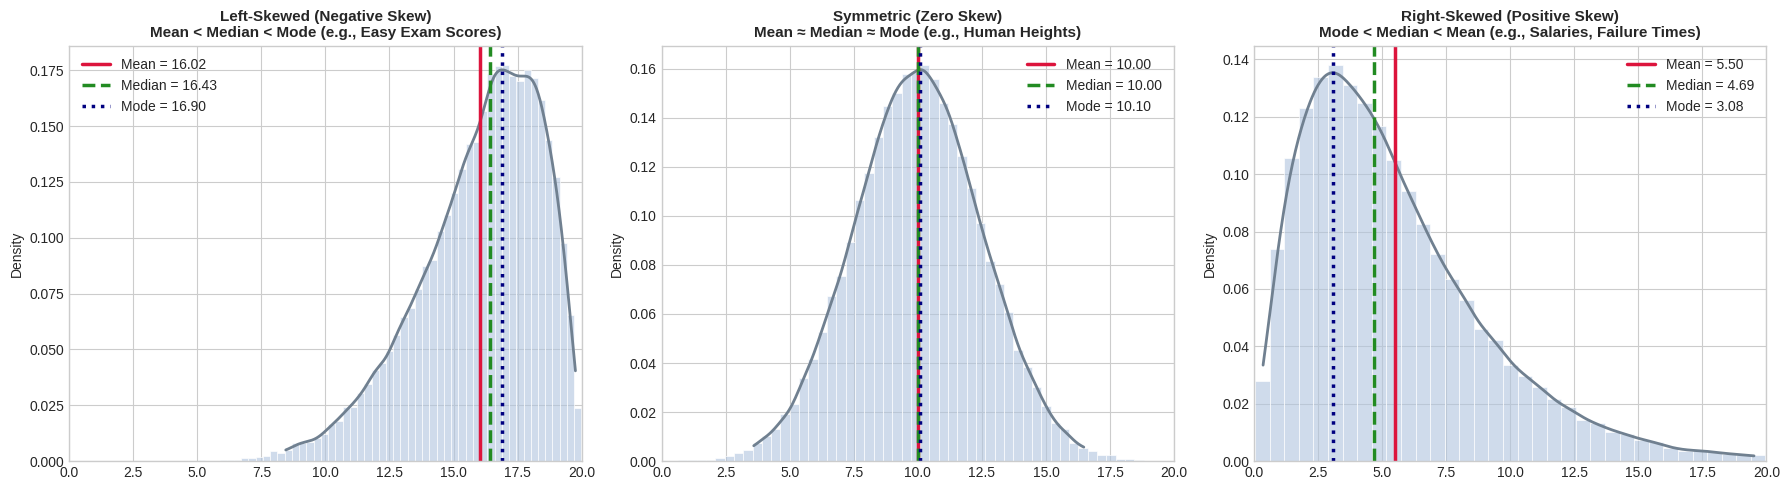

In [1]:
# ==============================================================================
# MODULE 0 (LEVEL 1A & 1B): MEAN, MEDIAN, MODE & THE BILLIONAIRE OUTLIER EFFECT
# ==============================================================================
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")

# 1. Our 7 Cafe Employees (in Lakhs)
salaries_normal = np.array([10, 12, 12, 15, 18, 20, 22])
salaries_billionaire = np.array([10, 12, 12, 15, 18, 20, 1000])

def summarize_center(arr: np.ndarray, name: str) -> dict:
    mode_res = stats.mode(arr, keepdims=True)
    return {
        "Scenario": name,
        "Data": str(arr.tolist()),
        "Mean (Balance Point)": np.mean(arr),
        "Median (Middle Value)": np.median(arr),
        "Mode (Most Frequent)": mode_res.mode[0]
    }

center_df = pd.DataFrame([
    summarize_center(salaries_normal, "1. Original 7 Employees"),
    summarize_center(salaries_billionaire, "2. With 1 Billionaire Outlier")
]).set_index("Scenario")

print("[HIGH SCHOOL STATS 1B: HOW AN OUTLIER DESTROYS THE MEAN BUT NOT THE MEDIAN]")
display(center_df.round(2))

# 2. Visualizing Left-Skewed vs Symmetric vs Right-Skewed (Mean vs Median vs Mode)
np.random.seed(42)
# Generate smooth synthetic distributions to see the exact geometry
x_grid = np.linspace(0, 20, 1000)

# Left-Skewed (Beta distribution with alpha=8, beta=2 scaled to 0-20)
left_skew_samples = stats.beta.rvs(a=8, b=2, scale=20, size=50_000)
# Symmetric (Normal distribution centered at 10)
sym_samples = stats.norm.rvs(loc=10, scale=2.5, size=50_000)
# Right-Skewed (Gamma / Log-normal style distribution)
right_skew_samples = stats.gamma.rvs(a=2.2, scale=2.5, size=50_000)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

datasets = [
    (left_skew_samples, "Left-Skewed (Negative Skew)\nMean < Median < Mode (e.g., Easy Exam Scores)"),
    (sym_samples, "Symmetric (Zero Skew)\nMean ≈ Median ≈ Mode (e.g., Human Heights)"),
    (right_skew_samples, "Right-Skewed (Positive Skew)\nMode < Median < Mean (e.g., Salaries, Failure Times)")
]

for ax, (data, title) in zip(axes, datasets):
    sns.histplot(data, stat="density", bins=60, ax=ax, color="lightsteelblue", edgecolor="white", alpha=0.6)

    # Compute kernel density to locate smooth peak (Mode)
    kde = stats.gaussian_kde(data)
    xs = np.linspace(np.percentile(data, 0.5), np.percentile(data, 99.5), 500)
    ys = kde(xs)
    ax.plot(xs, ys, color="slategray", lw=2)

    mean_v = np.mean(data)
    median_v = np.median(data)
    mode_v = xs[np.argmax(ys)]

    ax.axvline(mean_v, color="crimson", lw=2.5, ls="-", label=f"Mean = {mean_v:.2f}")
    ax.axvline(median_v, color="forestgreen", lw=2.5, ls="--", label=f"Median = {median_v:.2f}")
    ax.axvline(mode_v, color="navy", lw=2.5, ls=":", label=f"Mode = {mode_v:.2f}")

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlim(0, 20)
    ax.legend()

plt.tight_layout()
plt.show()

---

## Level 1C: Measures of Spread (Why the Center Alone Is Dangerous!)

> **The River Paradox:** *"A statistician drowned crossing a river that was, on average, only 3 feet deep."*

Suppose two batteries (Brand A and Brand B) are tested 5 times each for how many hours they last:
* **Brand A:** $[48, \; 49, \; 50, \; 51, \; 52]$ hours $\implies \text{Mean} = 50\text{ hrs}, \; \text{Median} = 50\text{ hrs}$
* **Brand B:** $[10, \; 30, \; 50, \; 70, \; 90]$ hours $\implies \text{Mean} = 50\text{ hrs}, \; \text{Median} = 50\text{ hrs}$

Both batteries have the **exact same Mean ($50$) and Median ($50$)**! Yet Brand A is rock-solid reliable, while Brand B might die in $10$ hours. To distinguish them, we need **Measures of Spread (Dispersion)**.

---

### 1. The Range (Simplest, but Fragile)
$$\text{Range} = \text{Max} - \text{Min}$$
* Brand A Range: $52 - 48 = 4\text{ hrs}$.
* Brand B Range: $90 - 10 = 80\text{ hrs}$.
* *Flaw:* Like the Mean, Range only looks at the **two most extreme points** and ignores everything in between.

---

### 2. Quartiles, the Interquartile Range (IQR) & Tukey's Boxplot
To avoid being fooled by extreme outliers at the ends, we chop our sorted data into **four equal quarters ($25\%$ chunks)**:
* **$Q_1$ (25th Percentile / First Quartile):** The median of the lower half of the data ($25\%$ of numbers are below $Q_1$).
* **$Q_2$ (50th Percentile / The Median):** Cuts the dataset in half ($50\%$ below, $50\%$ above).
* **$Q_3$ (75th Percentile / Third Quartile):** The median of the upper half ($75\%$ of numbers are below $Q_3$).

#### The Interquartile Range ($\text{IQR}$):
$$\text{IQR} = Q_3 - Q_1$$
* **Intuition:** The $\text{IQR}$ tells you the spread of the **middle $50\%$** of your data! Even if the top $24\%$ of numbers shoot off to infinity, $\text{IQR}$ does not budge.
* **John Tukey's $1.5 \times \text{IQR}$ Outlier Rule (How a Boxplot Flags Outliers):**
  Any data point that falls outside the "Fences" below is plotted as an individual outlier dot on a Boxplot:
  $$\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR}, \qquad \text{Upper Fence} = Q_3 + 1.5 \times \text{IQR}$$

---

### 3. Variance ($s^2$) and Standard Deviation ($s$) — Step-by-Step By Hand
How do we measure the average distance of *every* number from the Mean $\bar{x}$?
Let's take **Brand A**: $X = [48, 49, 50, 51, 52]$, where $\bar{x} = 50$.

**Step 1: Find the deviation of each point from the Mean ($x_i - \bar{x}$):**
$$[-2, \; -1, \; 0, \; +1, \; +2]$$
*Wait—what happens if we just average these deviations?*
$$(-2) + (-1) + 0 + (+1) + (+2) = \mathbf{0}$$
**The sum of deviations from the mean is ALWAYS zero** because positive and negative deviations cancel out!

**Step 2: How do we get rid of the minus signs?**
* **Option A (Absolute Value $\to$ Mean Absolute Deviation, MAD):** Take $|x_i - \bar{x}| \implies [2, 1, 0, 1, 2]$. Average $= \frac{6}{5} = 1.2\text{ hours}$. (Simple, robust, used in $L_1$ loss, but the absolute value $|x|$ has a sharp corner at $0$ where derivatives don't exist!).
* **Option B (Square each deviation $\to$ Variance, $s^2$):** Square each deviation $(x_i - \bar{x})^2$ so every number is positive AND smooth (differentiable everywhere for calculus!):
  $$(-2)^2 = 4, \quad (-1)^2 = 1, \quad 0^2 = 0, \quad (+1)^2 = 1, \quad (+2)^2 = 4$$
  Sum of Squares ($\text{SS}$) $= 4 + 1 + 0 + 1 + 4 = \mathbf{10}$.
  Divide by $n - 1 = 5 - 1 = 4$ (for a sample):
  $$\text{Sample Variance } s^2 = \frac{\sum_{i=1}^{n}(x_i - \bar{x})^2}{n - 1} = \frac{10}{4} = \mathbf{2.5\text{ hours}^2}$$

**Step 3: Take the Square Root to fix the units ($\to$ Standard Deviation, $s$):**
Notice that Variance is in **"squared hours" ($\text{hours}^2$)**, which has no physical intuition. Taking the square root brings us back to original **hours**:
$$\text{Standard Deviation } s = \sqrt{s^2} = \sqrt{2.5} \approx \mathbf{1.58\text{ hours}}$$

Now compare that to **Brand B** ($[10, 30, 50, 70, 90]$):
* Deviations from $50$: $[-40, -20, 0, +20, +40]$
* Squared Deviations: $[1600, 400, 0, 400, 1600] \implies \text{Sum} = 4000$
* Sample Variance $s^2 = \frac{4000}{4} = 1000\text{ hours}^2$
* Standard Deviation $s = \sqrt{1000} \approx \mathbf{31.62\text{ hours}}$ (20 times more spread out than Brand A!).

=== Brand A (Consistent Battery): [48, 49, 50, 51, 52] ===
  1. Mean (x_bar)                  : 50.00
  2. Deviations (x_i - x_bar)      : [-2.0, -1.0, 0.0, 1.0, 2.0]  (Sum = 0.0 -> Always 0!)
  3. Squared Deviations (x_i-x_bar)^2: [4.0, 1.0, 0.0, 1.0, 4.0]  (Sum of Squares = 10.0)
  4. Sample Variance s^2 = SS/(n-1): 10.0 / 4 = 2.50 (units squared)
  5. Standard Deviation s = sqrt(s^2): 1.58 (original units)

=== Brand B (Erratic Battery): [10, 30, 50, 70, 90] ===
  1. Mean (x_bar)                  : 50.00
  2. Deviations (x_i - x_bar)      : [-40.0, -20.0, 0.0, 20.0, 40.0]  (Sum = 0.0 -> Always 0!)
  3. Squared Deviations (x_i-x_bar)^2: [1600.0, 400.0, 0.0, 400.0, 1600.0]  (Sum of Squares = 4000.0)
  4. Sample Variance s^2 = SS/(n-1): 4000.0 / 4 = 1000.00 (units squared)
  5. Standard Deviation s = sqrt(s^2): 31.62 (original units)

[TUKEY'S BOXPLOT 5-NUMBER SUMMARY & 1.5*IQR OUTLIER RULE]
  Sorted Data : [12, 15, 17, 18, 20, 21, 22, 23, 25, 28, 52]
  Q1 (25%)    : 17.50 | Median (50

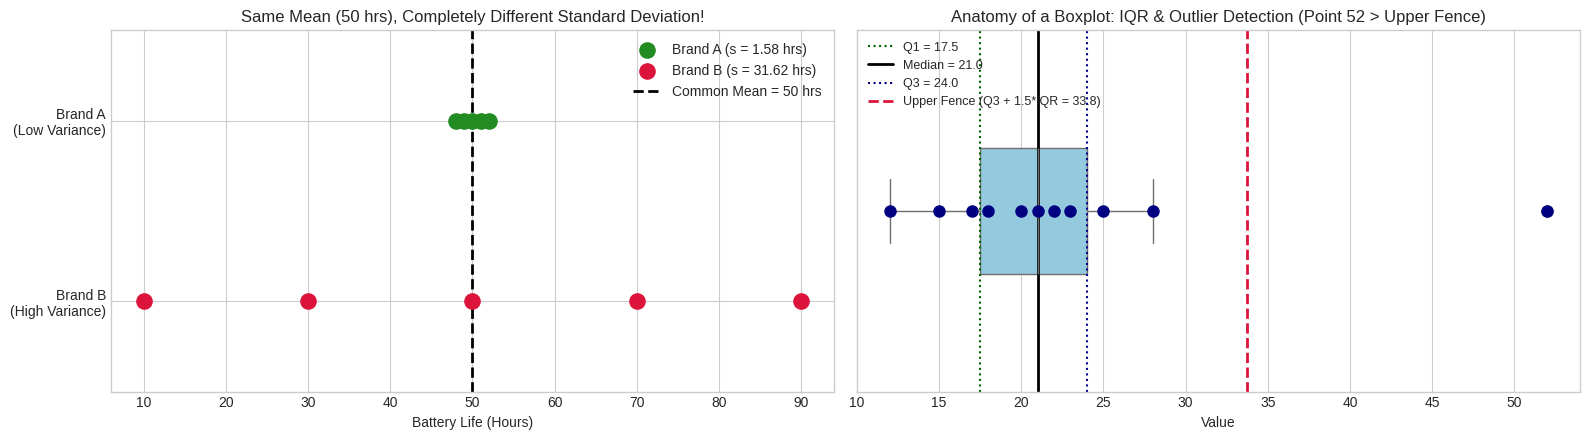

In [2]:
# ==============================================================================
# MODULE 0 (LEVEL 1C): STEP-BY-STEP VARIANCE, STD DEV & BOXPLOT ANATOMY
# ==============================================================================
brand_a = np.array([48, 49, 50, 51, 52])
brand_b = np.array([10, 30, 50, 70, 90])

def explain_spread_step_by_step(x: np.ndarray, label: str):
    mean_x = np.mean(x)
    deviations = x - mean_x
    sq_deviations = deviations ** 2
    sum_sq = np.sum(sq_deviations)
    var_sample = sum_sq / (len(x) - 1)
    std_sample = np.sqrt(var_sample)

    print(f"=== {label}: {x.tolist()} ===")
    print(f"  1. Mean (x_bar)                  : {mean_x:.2f}")
    print(f"  2. Deviations (x_i - x_bar)      : {deviations.tolist()}  (Sum = {np.sum(deviations):.1f} -> Always 0!)")
    print(f"  3. Squared Deviations (x_i-x_bar)^2: {sq_deviations.tolist()}  (Sum of Squares = {sum_sq:.1f})")
    print(f"  4. Sample Variance s^2 = SS/(n-1): {sum_sq:.1f} / {len(x)-1} = {var_sample:.2f} (units squared)")
    print(f"  5. Standard Deviation s = sqrt(s^2): {std_sample:.2f} (original units)\n")

explain_spread_step_by_step(brand_a, "Brand A (Consistent Battery)")
explain_spread_step_by_step(brand_b, "Brand B (Erratic Battery)")

# ------------------------------------------------------------------------------
# Visualizing Tukey's 5-Number Summary & Boxplot Fences with an Outlier
# ------------------------------------------------------------------------------
sample_with_outliers = np.array([12, 15, 17, 18, 20, 21, 22, 23, 25, 28, 52])
q1, median, q3 = np.percentile(sample_with_outliers, [25, 50, 75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outliers = sample_with_outliers[(sample_with_outliers < lower_fence) | (sample_with_outliers > upper_fence)]

print("[TUKEY'S BOXPLOT 5-NUMBER SUMMARY & 1.5*IQR OUTLIER RULE]")
print(f"  Sorted Data : {sample_with_outliers.tolist()}")
print(f"  Q1 (25%)    : {q1:.2f} | Median (50%): {median:.2f} | Q3 (75%): {q3:.2f}")
print(f"  IQR (Q3-Q1) : {iqr:.2f}")
print(f"  Fences      : [{lower_fence:.2f}, {upper_fence:.2f}] -> Detected Outliers: {outliers.tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

# Left: Brand A vs Brand B spread around the exact same mean (50)
axes[0].scatter(brand_a, [1]*len(brand_a), color="forestgreen", s=120, label="Brand A (s = 1.58 hrs)", zorder=3)
axes[0].scatter(brand_b, [0]*len(brand_b), color="crimson", s=120, label="Brand B (s = 31.62 hrs)", zorder=3)
axes[0].axvline(50, color="black", ls="--", lw=2, label="Common Mean = 50 hrs")
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["Brand B\n(High Variance)", "Brand A\n(Low Variance)"])
axes[0].set_ylim(-0.5, 1.5)
axes[0].set_xlabel("Battery Life (Hours)")
axes[0].set_title("Same Mean (50 hrs), Completely Different Standard Deviation!")
axes[0].legend()

# Right: Annotated Boxplot showing Q1, Median, Q3, Whiskers, and Outlier
sns.boxplot(x=sample_with_outliers, ax=axes[1], color="skyblue", width=0.35, fliersize=8)
sns.stripplot(x=sample_with_outliers, ax=axes[1], color="navy", size=9, jitter=False)
axes[1].axvline(q1, color="darkgreen", ls=":", lw=1.5, label=f"Q1 = {q1:.1f}")
axes[1].axvline(median, color="black", ls="-", lw=2, label=f"Median = {median:.1f}")
axes[1].axvline(q3, color="darkblue", ls=":", lw=1.5, label=f"Q3 = {q3:.1f}")
axes[1].axvline(upper_fence, color="crimson", ls="--", lw=2, label=f"Upper Fence (Q3 + 1.5*IQR = {upper_fence:.1f})")
axes[1].set_title("Anatomy of a Boxplot: IQR & Outlier Detection (Point 52 > Upper Fence)")
axes[1].set_xlabel("Value")
axes[1].legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

---

## Level 1D: High School Probability — Counting, Independence & Bayes' Paradox

Probability is the bridge from **describing data we already have** to **predicting data we haven't seen yet**.

### 1. Counting: Permutations (Order Matters) vs. Combinations (Order Doesn't Matter)
Suppose you have $n = 5$ distinct race cars ($A, B, C, D, E$) and want to pick $k = 3$ of them:
* **Permutations ($P(n, k)$ — Order Matters, e.g., Gold, Silver, Bronze medals):**
  First place has $5$ choices, second has $4$, third has $3$:
  $$P(n, k) = \frac{n!}{(n - k)!} = \frac{5!}{(5-3)!} = 5 \times 4 \times 3 = \mathbf{60\text{ ordered podiums}}$$
* **Combinations ($\binom{n}{k}$ — Order Does NOT Matter, e.g., picking 3 cars to put on a truck):**
  Since any 3 chosen cars $\{A, B, C\}$ can be rearranged among themselves in $k! = 3! = 6$ ways that all represent the exact same group, we divide by $k!$:
  $$\binom{n}{k} = \frac{n!}{k!(n - k)!} = \frac{60}{3!} = \frac{60}{6} = \mathbf{10\text{ unique groups}}$$

---

### 2. The #1 High School Trap: "Mutually Exclusive" vs. "Independent" Events
Many students (and even interviewees!) confuse these two terms—yet they are practically **opposites**:

* **Mutually Exclusive (Disjoint) Events ($A \cap B = \emptyset$):**
  Two events that **cannot happen at the same time** (e.g., flipping a single coin and getting *both* Heads and Tails on the same flip).
  * Addition Rule for Disjoint Events: $P(A \text{ or } B) = P(A \cup B) = P(A) + P(B)$.
  * *Notice:* If $A$ and $B$ have non-zero probability and are mutually exclusive, are they independent? **NO! They are maximally dependent!** Because if I tell you $A$ happened (the coin landed Heads), you immediately know with $100\%$ certainty that $B$ did **not** happen ($P(B \mid A) = 0 \ne P(B)$)!
* **Independent Events ($P(A \mid B) = P(A)$):**
  Knowing that $B$ happened gives you **zero information** about whether $A$ happened (e.g., flipping Heads on Coin 1 and rolling a 6 on a Die).
  * Multiplication Rule for Independent Events:
    $$P(A \text{ and } B) = P(A \cap B) = P(A) \times P(B)$$
  * General Addition Rule (when $A$ and $B$ CAN overlap):
    $$P(A \cup B) = P(A) + P(B) - P(A \cap B)$$
    *(We subtract $P(A \cap B)$ so we don't double-count the overlap!)*

---

### 3. Conditional Probability & Bayes' Theorem (The Rare Disease Paradox)
**Conditional Probability $P(A \mid B)$** reads: *"The probability of $A$ happening, **given that we already know $B$ happened**."*
By restricting our universe from everyone ($\Omega$) down to only the circle where $B$ happened:
$$P(A \mid B) = \frac{P(A \cap B)}{P(B)} \implies P(A \cap B) = P(A \mid B)P(B) = P(B \mid A)P(A)$$

Rearranging this gives **Bayes' Theorem**:
$$P(A \mid B) = \frac{P(B \mid A) P(A)}{P(B)}$$

#### Let's Solve the Classic Interview Question Without Formulas First (Using a Tree of 10,000 People!):
> **Problem:** A rare disease affects **$1\%$** of the population ($P(\text{Disease}) = 0.01$). A hospital builds a test that is **$99\%$ accurate**:
> * If you **have** the disease, the test says **"Positive" $99\%$ of the time** (Sensitivity = $99\%$).
> * If you are **healthy**, the test says **"Negative" $99\%$ of the time** (Specificity = $99\%$, meaning a $1\%$ False Positive rate).
>
> **You take the test and it comes back POSITIVE. What is the probability you actually have the disease?**
> *(90% of people guess $99\%$. Let's count 10,000 people to see why the true answer is only **$50\%$**!)*

1. Imagine a town of **$10,000$ people**:
   * **$1\%$ are Sick:** $100$ sick people.
   * **$99\%$ are Healthy:** $9,900$ healthy people.
2. Now test all $10,000$ people:
   * Among the **$100$ Sick people**, $99\%$ test Positive $\implies \mathbf{99\text{ True Positives}}$.
   * Among the **$9,900$ Healthy people**, $1\%$ falsely test Positive $\implies \mathbf{99\text{ False Positives}}$!
3. Total people who got a Positive test result $= 99\text{ (Sick)} + 99\text{ (Healthy)} = \mathbf{198\text{ people}}$.
4. Therefore, given you are in that group of $198$ Positive tests, your chance of actually being sick is:
   $$P(\text{Sick} \mid \text{Positive}) = \frac{99\text{ True Positives}}{99\text{ True Positives} + 99\text{ False Positives}} = \frac{99}{198} = \mathbf{50\%}!$$

[COUNTING] Choosing k=3 from n=5 items:
  Permutations P(5,3) (Order Matters - e.g. Podium)   : 60
  Combinations C(5,3) (Order Ignored - e.g. Committee): 10

[BAYES' THEOREM: THE 99% ACCURATE TEST PARADOX]
  Base Rate of Disease P(Sick)              : 1.00%
  Exact Bayes' Formula P(Sick | Positive)   : 50.00%
  Monte Carlo Simulation (1,000,000 people) : 49.92%


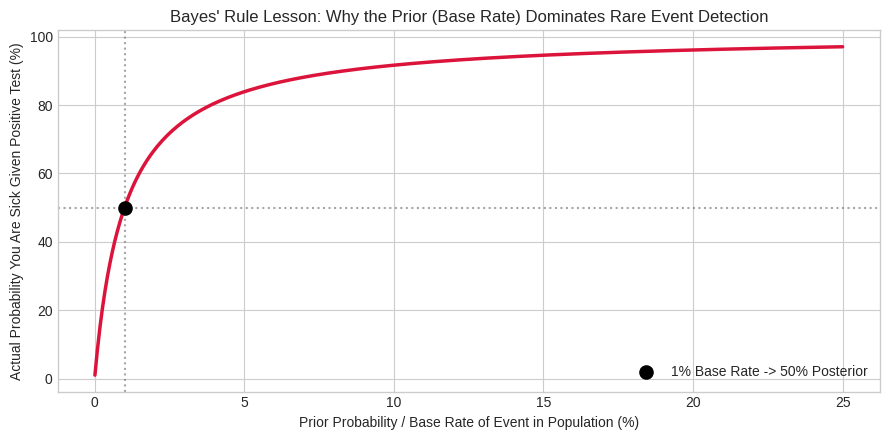

In [3]:
# ==============================================================================
# MODULE 0 (LEVEL 1D): COUNTING, INDEPENDENCE & BAYES' PARADOX SIMULATOR
# ==============================================================================
import math

# 1. Permutations vs Combinations for n=5 cars, choosing k=3
n, k = 5, 3
perm_nk = math.perm(n, k)   # 5! / (5-3)! = 60
comb_nk = math.comb(n, k)   # 5! / (3! * 2!) = 10
print(f"[COUNTING] Choosing k={k} from n={n} items:")
print(f"  Permutations P({n},{k}) (Order Matters - e.g. Podium)   : {perm_nk}")
print(f"  Combinations C({n},{k}) (Order Ignored - e.g. Committee): {comb_nk}\n")

# 2. Bayes' Theorem: Exact Formula vs 1,000,000-Person Monte Carlo Simulation
p_disease = 0.01          # Prior probability (Base rate = 1%)
p_pos_given_disease = 0.99 # Sensitivity (True Positive Rate = 99%)
p_pos_given_healthy = 0.01 # False Positive Rate (1 - Specificity = 1%)

# Law of Total Probability for P(Positive)
p_positive = (p_pos_given_disease * p_disease) + (p_pos_given_healthy * (1 - p_disease))
# Bayes' Rule for P(Disease | Positive)
p_disease_given_pos = (p_pos_given_disease * p_disease) / p_positive

# Verify by simulating 1,000,000 virtual citizens
np.random.seed(42)
N_pop = 1_000_000
is_sick = np.random.rand(N_pop) < p_disease
test_positive = np.where(
    is_sick,
    np.random.rand(N_pop) < p_pos_given_disease,
    np.random.rand(N_pop) < p_pos_given_healthy
)

sim_posterior = np.mean(is_sick[test_positive])

print("[BAYES' THEOREM: THE 99% ACCURATE TEST PARADOX]")
print(f"  Base Rate of Disease P(Sick)              : {p_disease*100:.2f}%")
print(f"  Exact Bayes' Formula P(Sick | Positive)   : {p_disease_given_pos*100:.2f}%")
print(f"  Monte Carlo Simulation (1,000,000 people) : {sim_posterior*100:.2f}%")

# Plot how P(Sick | Positive) changes as the Disease Base Rate (Prior) changes
priors = np.linspace(0.0001, 0.25, 300)
posteriors = (p_pos_given_disease * priors) / (
    p_pos_given_disease * priors + p_pos_given_healthy * (1 - priors)
)

plt.figure(figsize=(9, 4.5))
plt.plot(priors * 100, posteriors * 100, color="crimson", lw=2.5)
plt.scatter([1.0], [50.0], color="black", s=90, zorder=5, label="1% Base Rate -> 50% Posterior")
plt.axhline(50, color="gray", ls=":", alpha=0.7)
plt.axvline(1.0, color="gray", ls=":", alpha=0.7)
plt.title("Bayes' Rule Lesson: Why the Prior (Base Rate) Dominates Rare Event Detection", fontsize=12)
plt.xlabel("Prior Probability / Base Rate of Event in Population (%)")
plt.ylabel("Actual Probability You Are Sick Given Positive Test (%)")
plt.legend()
plt.tight_layout()
plt.show()

---

# Module 0 — Level 2: College Statistics I (Random Variables & The 5 Fundamental Distributions)

## Level 2A: What Is a Random Variable? (Discrete vs. Continuous)

A **Random Variable ($X$)** is simply a variable whose value is the numerical outcome of a random phenomenon. They come in two flavors:

1. **Discrete Random Variable (Counting):**
   * Takes **countable, separate values** (usually integers: $0, 1, 2, 3, \dots$). There is nothing in between $1$ and $2$ (you cannot flip $1.42$ heads or have $2.7$ defective bolts).
   * Described by a **Probability Mass Function (PMF)**, $P(X = k)$, which gives the exact probability of landing on number $k$. All bars must sum to $1$: $\sum_k P(X = k) = 1$.
2. **Continuous Random Variable (Measuring):**
   * Can take **any decimal value on a continuum** (e.g., exact time until a lightbulb burns out: $142.839102\dots\text{ hours}$, or exact temperature).
   * Described by a **Probability Density Function (PDF)**, $f(x)$.
   * **Why is $P(X = \text{exact number}) = 0$ for continuous variables?**
     Imagine asking: *"What is the probability a person is **exactly** $175.000000000\dots\text{ cm}$ tall down to infinite decimal places?"* Zero! Instead, for continuous variables, **probability is the AREA under the curve between two points**:
     $$P(a \le X \le b) = \int_{a}^{b} f(x)\,dx$$

---

## Level 2B: The 3 Fundamental Discrete Distributions (Bernoulli, Binomial, Poisson)

Think of these three discrete distributions as a single family that evolves from **one coin flip**, to **$n$ coin flips**, to **counting events over continuous time**:

### 1. The Bernoulli Distribution — $\text{Bernoulli}(p)$ (A Single Yes/No Trial)
* **The Story:** You run **1 single trial** that can only result in Success ($X = 1$, with probability $p$) or Failure ($X = 0$, with probability $1 - p$).
* **Simple Example:** A basketball player shoots **1 free throw** with an $80\%$ make rate ($p = 0.8$).
* **PMF Formula:**
  $$P(X = k) = p^k (1 - p)^{1 - k} \quad \text{for } k \in \{0, 1\}$$
* **Mean & Variance:**
  $$\mathbb{E}[X] = p, \qquad \text{Var}(X) = p(1 - p)$$
  *(Notice: When is uncertainty/variance highest? When $p = 0.5 \implies 0.5 \times 0.5 = 0.25$. If $p = 1$ or $p = 0$, outcome is guaranteed, so $\text{Var}(X) = 0$!)*

---

### 2. The Binomial Distribution — $\text{Binomial}(n, p)$ (Sum of $n$ Independent Bernoulli Trials)
* **The Story:** You repeat that $\text{Bernoulli}(p)$ trial **$n$ independent times** and count the total number of successes $X \in \{0, 1, \dots, n\}$.
* **Simple Example:** You flip a biased coin ($p = 0.3$ chance of Heads) **$n = 10$ times**. What is the probability of getting **exactly $k = 3$ Heads**?
  * Any *single* specific sequence of 3 Heads and 7 Tails (like `HHHTTTTTTT`) has probability $p^3 (1-p)^7$.
  * But those 3 Heads could happen on any 3 of the 10 flips! From Level 1D, there are $\binom{10}{3} = 120$ ways to choose which 3 flips are Heads.
* **PMF Formula:**
  $$P(X = k) = \binom{n}{k} p^k (1 - p)^{n - k}$$
* **Mean & Variance (Just multiply the single Bernoulli trial by $n$!):**
  $$\mathbb{E}[X] = np, \qquad \text{Var}(X) = np(1 - p)$$

---

### 3. The Poisson Distribution — $\text{Poisson}(\lambda)$ (Counting Rare Events in a Fixed Window)
* **The Story:** What if you are counting how many times an event happens inside a fixed window of **time** or **space** (e.g., number of customers entering a shop per hour, or number of potholes per kilometer of road)?
  * Here, we don't have a fixed number of trials $n$—an event could theoretically happen at *any* millisecond ($n \to \infty$), while the probability of it happening in any single millisecond is tiny ($p \to 0$), such that the average rate $\lambda = np$ stays constant!
* **Simple Example:** A call center receives an average of $\lambda = 4$ calls per hour. What is the probability they receive **exactly $k = 6$ calls** in the next hour?
* **PMF Formula:**
  $$P(X = k) = \frac{\lambda^k e^{-\lambda}}{k!} \quad \text{for } k \in \{0, 1, 2, \dots\}$$
* **Mean & Variance (The Famous Poisson Identity):**
  $$\mathbb{E}[X] = \lambda, \qquad \text{Var}(X) = \lambda$$
  *Senior DS Tip:* In a true Poisson process, the **Mean equals the Variance** ($\mu = \sigma^2 = \lambda$). In real life, if you count website clicks or component failures and find $\text{Variance} \gg \text{Mean}$, that is called **Overdispersion** (and you switch from Poisson to the **Negative Binomial** distribution!).

[DISCRETE DISTRIBUTIONS: EXACT PROBABILITIES]
  1. Binomial(n=10, p=0.3) -> P(Exactly 3 Heads)   = 0.2668 (26.68%) | Expected = 3.0, Var = 2.10
  2. Poisson(lambda=4.0)   -> P(Exactly 6 Calls)   = 0.1042 (10.42%) | Expected = 4.0, Var = 4.00



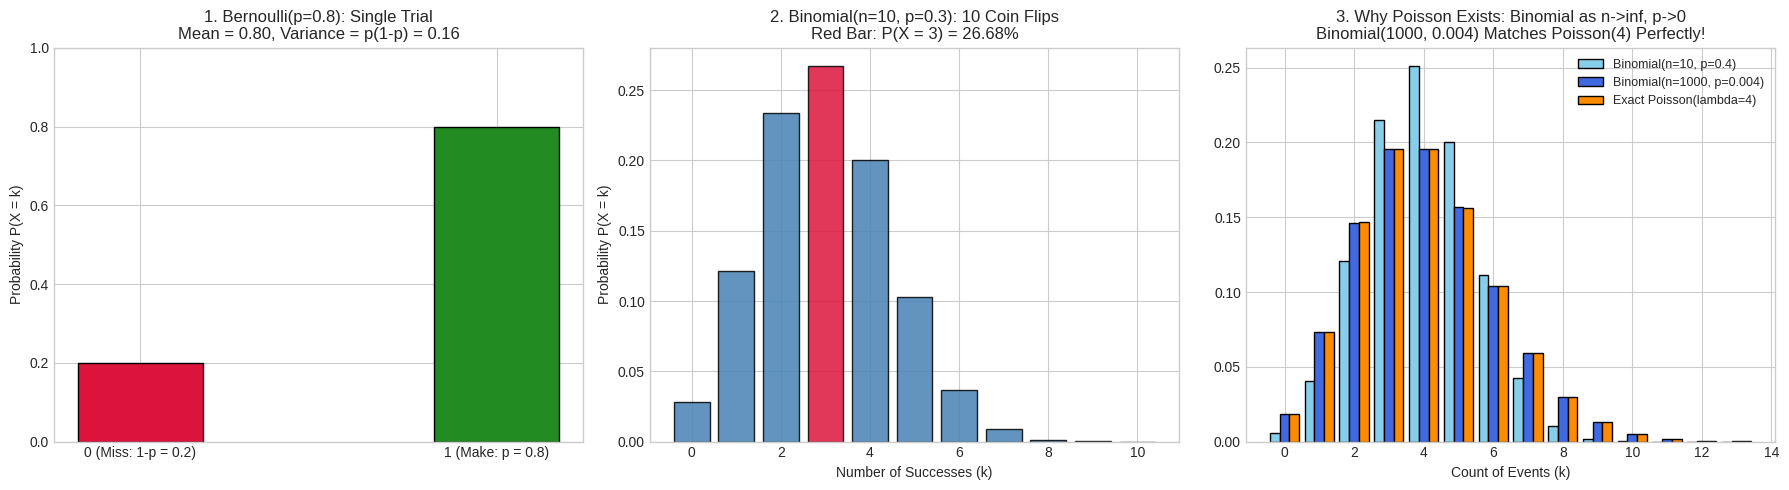

In [4]:
# ==============================================================================
# MODULE 0 (LEVEL 2B): BERNOULLI, BINOMIAL & POISSON DISTRIBUTIONS IN ACTION
# ==============================================================================
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

# 1. Concrete Hand-Calculable Examples
# Example A: Binomial(n=10 coin flips, p=0.3 chance of Heads) -> P(X = 3)
n_flips, p_heads = 10, 0.3
k_target = 3
prob_binom_3 = stats.binom.pmf(k=k_target, n=n_flips, p=p_heads)

# Example B: Poisson(lambda=4 calls/hour) -> P(X = 6 calls in an hour)
lam_calls = 4.0
k_calls = 6
prob_poiss_6 = stats.poisson.pmf(k=k_calls, mu=lam_calls)

print("[DISCRETE DISTRIBUTIONS: EXACT PROBABILITIES]")
print(f"  1. Binomial(n=10, p=0.3) -> P(Exactly 3 Heads)   = {prob_binom_3:.4f} ({prob_binom_3*100:.2f}%) | Expected = {n_flips*p_heads:.1f}, Var = {n_flips*p_heads*(1-p_heads):.2f}")
print(f"  2. Poisson(lambda=4.0)   -> P(Exactly 6 Calls)   = {prob_poiss_6:.4f} ({prob_poiss_6*100:.2f}%) | Expected = {lam_calls:.1f}, Var = {lam_calls:.2f}\n")

# 2. Prove Visually How Binomial(n, p) Converges to Poisson(lambda = n*p) as n -> infinity
# Suppose average rate is lambda = 4 events/hour.
# Compare: splitting the hour into n=10 chunks (p=0.4) vs n=1000 chunks (p=0.004) vs exact Poisson(4)
k_vals = np.arange(0, 14)
pmf_binom_n10 = stats.binom.pmf(k_vals, n=10, p=4/10)
pmf_binom_n1000 = stats.binom.pmf(k_vals, n=1000, p=4/1000)
pmf_poisson = stats.poisson.pmf(k_vals, mu=4.0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Bernoulli(p=0.8) Free Throw
axes[0].bar([0, 1], [0.2, 0.8], width=0.35, color=["crimson", "forestgreen"], edgecolor="black")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["0 (Miss: 1-p = 0.2)", "1 (Make: p = 0.8)"])
axes[0].set_ylim(0, 1.0)
axes[0].set_title("1. Bernoulli(p=0.8): Single Trial\nMean = 0.80, Variance = p(1-p) = 0.16")
axes[0].set_ylabel("Probability P(X = k)")

# Plot 2: Binomial(n=10, p=0.3)
k_10 = np.arange(0, 11)
colors_b = ["crimson" if k == 3 else "steelblue" for k in k_10]
axes[1].bar(k_10, stats.binom.pmf(k_10, n=10, p=0.3), color=colors_b, edgecolor="black", alpha=0.85)
axes[1].set_title("2. Binomial(n=10, p=0.3): 10 Coin Flips\nRed Bar: P(X = 3) = 26.68%")
axes[1].set_xlabel("Number of Successes (k)")
axes[1].set_ylabel("Probability P(X = k)")

# Plot 3: Binomial -> Poisson Convergence (Law of Rare Events)
width = 0.28
axes[2].bar(k_vals - width, pmf_binom_n10, width=width, label="Binomial(n=10, p=0.4)", color="skyblue", edgecolor="k")
axes[2].bar(k_vals, pmf_binom_n1000, width=width, label="Binomial(n=1000, p=0.004)", color="royalblue", edgecolor="k")
axes[2].bar(k_vals + width, pmf_poisson, width=width, label="Exact Poisson(lambda=4)", color="darkorange", edgecolor="k")
axes[2].set_title("3. Why Poisson Exists: Binomial as n->inf, p->0\nBinomial(1000, 0.004) Matches Poisson(4) Perfectly!")
axes[2].set_xlabel("Count of Events (k)")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

---

## Level 2C: The 2 Fundamental Continuous Distributions (Exponential & Normal)

### 4. The Exponential Distribution — $\text{Exponential}(\lambda)$ (Waiting Time Between Poisson Events)
* **The Story:** If events arrive according to a $\text{Poisson}(\lambda)$ process (say $\lambda = 4$ calls per hour, or $\lambda = 0.01$ meteors per year), how long is the **continuous waiting time $T$** until the next event occurs?
  * **Poisson (Discrete)** counts *how many events* happen in a fixed time window: $X \sim \text{Poisson}(\lambda)$.
  * **Exponential (Continuous)** measures *how much time passes* between two consecutive events: $T \sim \text{Exponential}(\lambda)$.
* **PDF & CDF Formulas:**
  $$f(t) = \lambda e^{-\lambda t}, \qquad F(t) = P(T \le t) = 1 - e^{-\lambda t} \quad (t \ge 0)$$
* **Mean & Variance:**
  $$\mathbb{E}[T] = \frac{1}{\lambda} \quad (\text{called Mean Time Between Failures, MTBF}), \qquad \text{Var}(T) = \frac{1}{\lambda^2}$$
  *(Check the intuition: If $\lambda = 4$ calls arrive per hour, then the average waiting time between calls is $\frac{1}{\lambda} = \frac{1}{4}\text{ hour} = 15\text{ minutes}$!)*
* **The Famous "Memoryless Property":**
  The Exponential distribution is the **only** continuous distribution with zero memory of the past:
  $$P(T > t + s \mid T > s) = P(T > t)$$
  *What does this mean?* Suppose a lightbulb follows an Exponential lifetime with average life $100$ hours. If it has already survived $s = 500$ hours without burning out, its probability of surviving the *next* $t = 50$ hours is **identical to a brand-new lightbulb straight out of the box**! (Because Exponential assumes no mechanical wear-out—only random external shocks like lightning spikes).

---

### 5. The Normal (Gaussian) Distribution — $\mathcal{N}(\mu, \sigma^2)$ (The Bell Curve)
* **The Story:** Whenever a measurement (human height, blood pressure, thermometer error, exam scores) is the sum of many tiny, independent random nudges (genetics, nutrition, environment), the Central Limit Theorem forces the result into a symmetric **Bell Curve** centered at mean $\mu$ with spread $\sigma$:
  $$f(x) = \frac{1}{\sigma\sqrt{2\pi}} \exp\left( -\frac{1}{2}\left(\frac{x - \mu}{\sigma}\right)^2 \right)$$

---

### 6. Z-Scores (Standardization) & The 68–95–99.7% Empirical Rule

#### Why Do We Need a Z-Score? (Comparing Apples and Oranges)
> **Question:** Rahul scored **$680$** on the SAT (where the national Mean is $\mu = 500$ and Standard Deviation is $\sigma = 100$). Priya scored **$29$** on the ACT (where the national Mean is $\mu = 21$ and Standard Deviation is $\sigma = 5$). **Who performed better relative to their peers?**

You cannot compare $680$ to $29$ directly! Instead, we convert both scores into a **Z-Score** (also called a **Standard Score**), which answers:
> **"How many Standard Deviations ($\sigma$) above or below the Mean ($\mu$) is this value?"**
$$Z = \frac{X - \mu}{\sigma}$$

Let's calculate both Z-scores by hand:
* **Rahul's Z-Score:** $Z_{\text{Rahul}} = \frac{680 - 500}{100} = \frac{180}{100} = \mathbf{+1.80}$ ($1.80$ standard deviations above average).
* **Priya's Z-Score:** $Z_{\text{Priya}} = \frac{29 - 21}{5} = \frac{8}{5} = \mathbf{+1.60}$ ($1.60$ standard deviations above average).
* **Winner:** **Rahul ($Z = +1.80 > +1.60$)** performed better!

When you transform *any* Normal distribution $X \sim \mathcal{N}(\mu, \sigma^2)$ using $Z = \frac{X - \mu}{\sigma}$, it becomes the **Standard Normal Distribution** $Z \sim \mathcal{N}(0, 1)$ (Mean $= 0$, Standard Deviation $= 1$).

#### The 68–95–99.7% Empirical Rule (Memorize This for Every Interview!):
For any Normal distribution $\mathcal{N}(\mu, \sigma^2)$:
* **$\mu \pm 1\sigma$ ($|Z| \le 1$):** Contains **$68.27\%$** of all data (roughly $\frac{2}{3}$ of observations).
* **$\mu \pm 2\sigma$ ($|Z| \le 2$):** Contains **$95.45\%$** of all data (More precisely, **$95.0\%$** of the area lies within **$\mu \pm 1.96\sigma$**—that is where the famous **$1.96$** in $95\%$ confidence intervals comes from!).
* **$\mu \pm 3\sigma$ ($|Z| \le 3$):** Contains **$99.73\%$** of all data (Only $0.27\%$—or roughly $1\text{ in }370$ normal observations—falls beyond $\pm 3\sigma$, which is why industrial quality control uses **$3\sigma$ Shewhart control limits** to flag anomalies!).

[EXPONENTIAL DISTRIBUTION: PROVING THE MEMORYLESS PROPERTY]
  Exact Theoretical P(T > 15)               : 0.2231
  Simulated Fresh Wait P(T > 15)            : 0.2234
  Simulated P(T > 35 | Already Waited 20)   : 0.2226 (Identical! No memory of the past 20 mins!)

[Z-SCORE STANDARDIZATION: COMPARING APPLES & ORANGES]
  Rahul (SAT 680, mu=500, sigma=100) -> Z = +1.80 (Top 3.59%, 96.41th percentile)
  Priya (ACT 29,  mu=21,  sigma=5)   -> Z = +1.60 (Top 5.48%, 94.52th percentile)



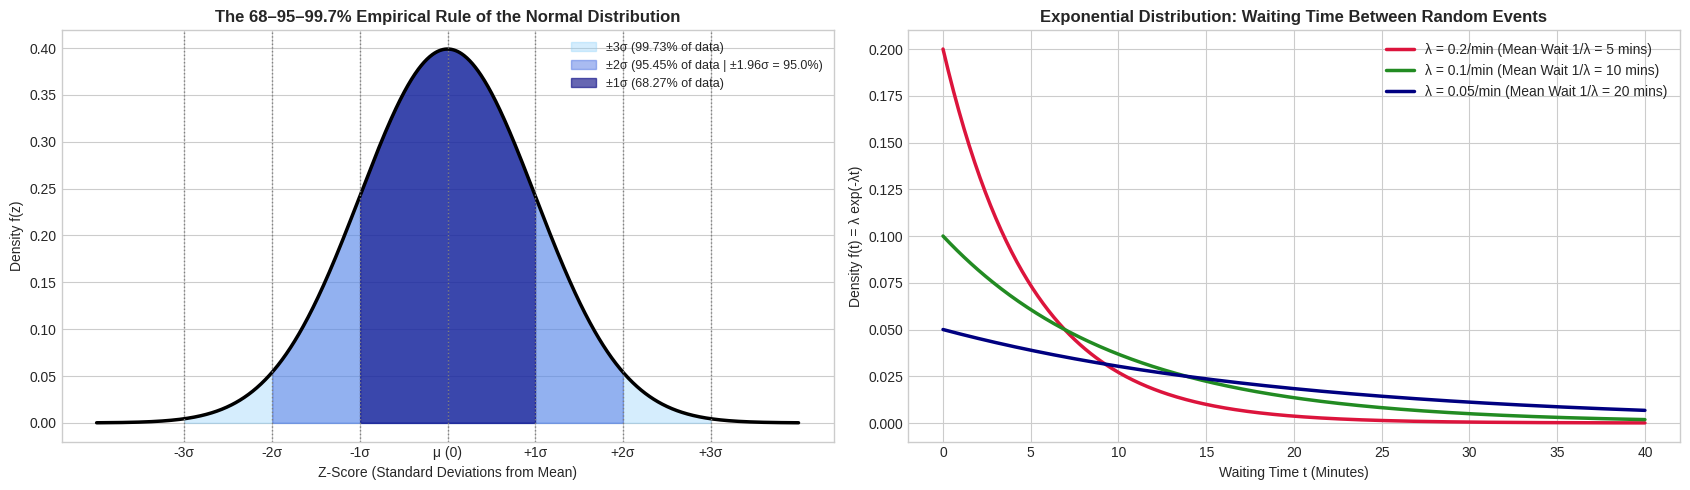

In [5]:
# ==============================================================================
# MODULE 0 (LEVEL 2C): EXPONENTIAL MEMORYLESSNESS, Z-SCORES & 68-95-99.7% RULE
# ==============================================================================
# 1. Exponential Memoryless Property Proof by Simulation
# Suppose average waiting time between bus arrivals is 10 minutes (lambda = 1/10 = 0.1/min)
np.random.seed(42)
mean_wait = 10.0
waits = np.random.exponential(scale=mean_wait, size=500_000)

# Unconditional probability you wait MORE than 15 minutes from scratch: P(T > 15)
p_wait_gt_15 = np.mean(waits > 15.0)

# Conditional probability: Given you have ALREADY waited 20 minutes, what is the probability
# you have to wait at least 15 MORE minutes? P(T > 20 + 15 | T > 20)
already_waited_20 = waits[waits > 20.0]
p_wait_15_more_given_20 = np.mean(already_waited_20 > (20.0 + 15.0))

print("[EXPONENTIAL DISTRIBUTION: PROVING THE MEMORYLESS PROPERTY]")
print(f"  Exact Theoretical P(T > 15)               : {np.exp(-15.0/mean_wait):.4f}")
print(f"  Simulated Fresh Wait P(T > 15)            : {p_wait_gt_15:.4f}")
print(f"  Simulated P(T > 35 | Already Waited 20)   : {p_wait_15_more_given_20:.4f} (Identical! No memory of the past 20 mins!)\n")

# 2. Z-Score Standardization: Comparing Rahul (SAT) vs Priya (ACT)
z_rahul = (680 - 500) / 100
z_priya = (29 - 21) / 5
pct_rahul = stats.norm.cdf(z_rahul) * 100
pct_priya = stats.norm.cdf(z_priya) * 100

print("[Z-SCORE STANDARDIZATION: COMPARING APPLES & ORANGES]")
print(f"  Rahul (SAT 680, mu=500, sigma=100) -> Z = +{z_rahul:.2f} (Top {100-pct_rahul:.2f}%, {pct_rahul:.2f}th percentile)")
print(f"  Priya (ACT 29,  mu=21,  sigma=5)   -> Z = +{z_priya:.2f} (Top {100-pct_priya:.2f}%, {pct_priya:.2f}th percentile)\n")

# 3. Visualizing the 68 - 95 - 99.7% Empirical Rule on Standard Normal N(0, 1)
z = np.linspace(-4, 4, 1000)
pdf_z = stats.norm.pdf(z)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# Left Plot: The 68 - 95 - 99.7% Bell Curve
axes[0].plot(z, pdf_z, color="black", lw=2.5)
axes[0].fill_between(z, pdf_z, where=(np.abs(z) <= 3), color="lightskyblue", alpha=0.35, label="±3σ (99.73% of data)")
axes[0].fill_between(z, pdf_z, where=(np.abs(z) <= 2), color="royalblue", alpha=0.45, label="±2σ (95.45% of data | ±1.96σ = 95.0%)")
axes[0].fill_between(z, pdf_z, where=(np.abs(z) <= 1), color="navy", alpha=0.60, label="±1σ (68.27% of data)")

for sigma_val in [-3, -2, -1, 0, 1, 2, 3]:
    axes[0].axvline(sigma_val, color="gray", ls=":", lw=1)

axes[0].set_xticks([-3, -2, -1, 0, 1, 2, 3])
axes[0].set_xticklabels(["-3σ", "-2σ", "-1σ", "μ (0)", "+1σ", "+2σ", "+3σ"])
axes[0].set_title("The 68–95–99.7% Empirical Rule of the Normal Distribution", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Z-Score (Standard Deviations from Mean)")
axes[0].set_ylabel("Density f(z)")
axes[0].legend(loc="upper right", fontsize=9)

# Right Plot: Connection Between Poisson Arrival Counts & Exponential Waiting Times
t_vals = np.linspace(0, 40, 400)
for lam, col in [(0.2, "crimson"), (0.1, "forestgreen"), (0.05, "navy")]:
    axes[1].plot(t_vals, stats.expon.pdf(t_vals, scale=1/lam), color=col, lw=2.5,
                 label=f"λ = {lam}/min (Mean Wait 1/λ = {1/lam:.0f} mins)")

axes[1].set_title("Exponential Distribution: Waiting Time Between Random Events", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Waiting Time t (Minutes)")
axes[1].set_ylabel("Density f(t) = λ exp(-λt)")
axes[1].legend()

plt.tight_layout()
plt.show()

---

# Module 0 — Level 3: College Statistics II (Statistical Inference & Hypothesis Testing)

## Level 3A: From a Small Sample to the Whole Population (Standard Error, Student's $t$, and Confidence Intervals)

### 1. Standard Deviation ($s$) vs. Standard Error ($\text{SE}$) — The Most Common Confusion
Suppose we want to know the average height $\mu$ of all $1.4\text{ billion}$ people in India, so we measure a random sample of $n = 25$ people.
* **Sample Standard Deviation ($s$):** How much *individual people* vary from each other (e.g., $s = 10\text{ cm}$).
* **Standard Error of the Mean ($\text{SE}$):** How much our *sample average $\bar{x}$* would bounce around if we repeated this 25-person survey over and over:
  $$\text{SE}(\bar{x}) = \frac{s}{\sqrt{n}} = \frac{10}{\sqrt{25}} = \frac{10}{5} = \mathbf{2\text{ cm}}$$

---

### 2. Why Did Guinness Brewery Invent Student's $t$-Distribution in 1908?
If we knew the true population standard deviation $\sigma$, then by the Central Limit Theorem:
$$Z = \frac{\bar{X} - \mu}{\sigma / \sqrt{n}} \sim \mathcal{N}(0, 1)$$

**The Catch:** In 1908, **William Sealy Gosset**, Head Experimental Brewer at the **Guinness Brewery** in Dublin, was testing the chemical quality of barley batches. Because lab testing was expensive, his sample sizes were tiny ($n = 3$ or $n = 5$ barrels).
* He did **not** know the true population $\sigma$—he had to estimate it using the sample standard deviation $s$ from those same $n=4$ barrels!
* When $n$ is small, $s$ is itself a noisy random variable that occasionally gets unusually small, causing the ratio:
  $$t = \frac{\bar{X} - \mu}{s / \sqrt{n}}$$
  to blow up and produce extreme values much more often than a Normal $\mathcal{N}(0, 1)$ curve predicts!
* Because Guinness forbade employees from publishing trade secrets, Gosset published his discovery under the pen name **"Student"**, calling it **Student's $t$-Distribution with $\nu = n - 1$ Degrees of Freedom (df)**:
  * **Heavy Tails for Small $n$:** When $\text{df} = n - 1$ is small, the $t$-distribution has **fatter tails** than $\mathcal{N}(0, 1)$ to account for the extra uncertainty of estimating $s$.
  * **Converges to Normal as $n \to \infty$:** Once $n > 30$ (and definitely by $n = 100$), $s \approx \sigma$, and the $t$-distribution becomes virtually identical to the Standard Normal $\mathcal{N}(0, 1)$ ($t_{0.975, \infty} = 1.96$).

---

### 3. Confidence Intervals (What "95% Confident" Actually Means!)
Using Student's $t$-distribution, the **$95\%$ Confidence Interval (CI)** for the true population mean $\mu$ is:
$$\text{CI}_{95\%} = \bar{x} \pm t_{\alpha/2, \, n-1} \cdot \left(\frac{s}{\sqrt{n}}\right)$$

#### The Famous Interview Trap:
> **Question:** Suppose we compute a $95\%$ Confidence Interval for average battery life and get $[48.2, \, 51.8]$ hours. Does that mean *"There is a $95\%$ probability that the true mean $\mu$ lies between $48.2$ and $51.8$"*?
>
> **Answer:** **NO!** In Frequentist statistics, the true population mean $\mu$ is a **fixed, non-random constant** (say $\mu = 50.0$). It is either inside $[48.2, 51.8]$ ($100\%$ probability) or it isn't ($0\%$ probability)!
> * **What is random?** **Your interval endpoints $[L, U]$ are random** because they depend on the random sample $\bar{x}$ and $s$!
> * **Correct Definition:** *"If we repeated this sampling experiment $100$ times and built $100$ separate confidence intervals, **approximately $95$ out of those $100$ intervals would successfully capture the true fixed parameter $\mu$** (and about $5$ would miss it!)."*

[WHY SMALL SAMPLES NEED STUDENT'S t MULTIPLIER INSTEAD OF 1.96]


,Degrees of Freedom (df = n - 1),"95% t-Critical Multiplier (t_0.025, df)",Naive Normal Multiplier (Z_0.025)
Sample Size (n = df + 1),,,
3,2,4.3027,1.96
5,4,2.7764,1.96
10,9,2.2622,1.96
30,29,2.0452,1.96
100,99,1.9842,1.96
1001,1000,1.9623,1.96


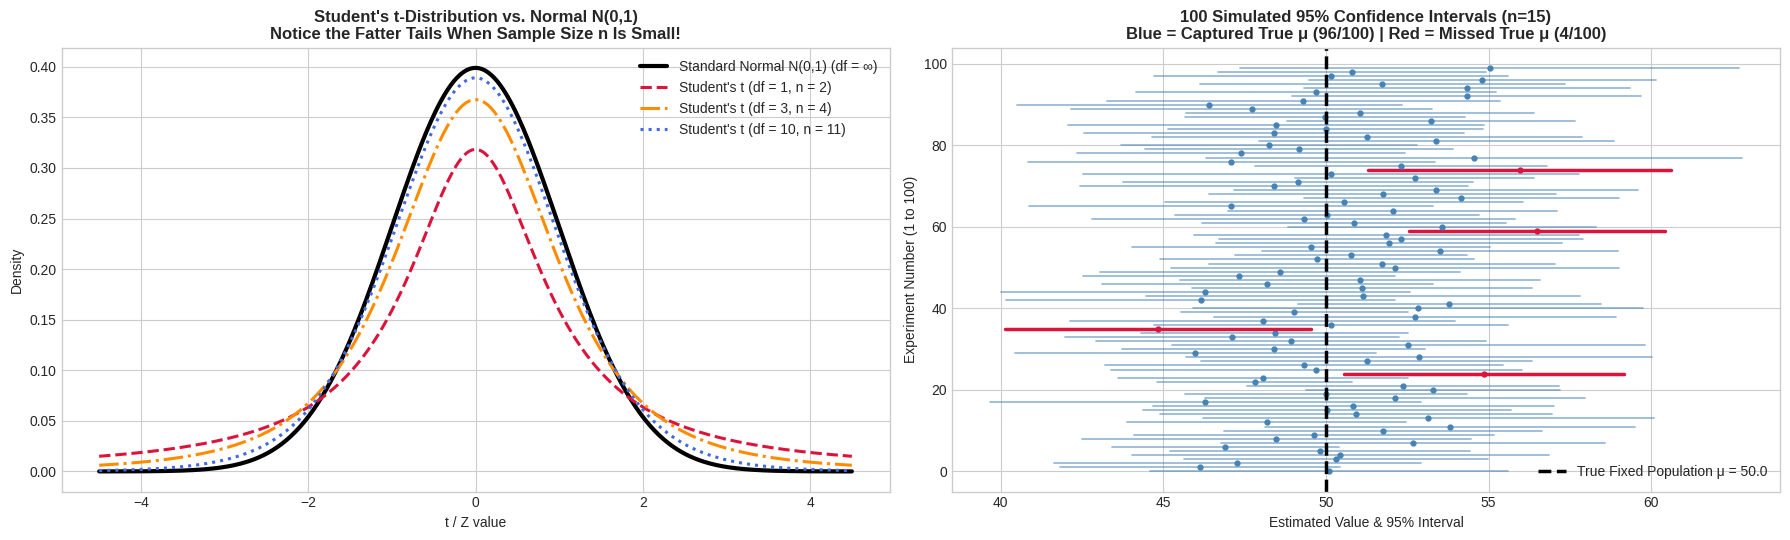

In [6]:
# ==============================================================================
# MODULE 0 (LEVEL 3A): GUINNESS BREWERY'S t-DISTRIBUTION & 100 CONFIDENCE INTERVALS
# ==============================================================================
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)

# 1. Compare Critical Multipliers for 95% CI: Normal (1.96) vs Student's t for small n
df_list = [2, 4, 9, 29, 99, 1000]
t_table = []
for df in df_list:
    t_crit = stats.t.ppf(0.975, df=df)  # Two-tailed 95% leaves 2.5% in each tail (0.975)
    t_table.append({
        "Sample Size (n = df + 1)": df + 1,
        "Degrees of Freedom (df = n - 1)": df,
        "95% t-Critical Multiplier (t_0.025, df)": t_crit,
        "Naive Normal Multiplier (Z_0.025)": 1.95996
    })
print("[WHY SMALL SAMPLES NEED STUDENT'S t MULTIPLIER INSTEAD OF 1.96]")
display(pd.DataFrame(t_table).set_index("Sample Size (n = df + 1)").round(4))

# 2. Plot Student's t-Distribution (Heavy Tails) vs Standard Normal N(0,1) + Simulate 100 CIs
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

# Left Plot: PDF of t-distribution vs Normal
x_grid = np.linspace(-4.5, 4.5, 500)
axes[0].plot(x_grid, stats.norm.pdf(x_grid), color="black", lw=3, label="Standard Normal N(0,1) (df = ∞)")
for df, col, ls in [(1, "crimson", "--"), (3, "darkorange", "-."), (10, "royalblue", ":")]:
    axes[0].plot(x_grid, stats.t.pdf(x_grid, df=df), color=col, lw=2.2, ls=ls, label=f"Student's t (df = {df}, n = {df+1})")

axes[0].set_title("Student's t-Distribution vs. Normal N(0,1)\nNotice the Fatter Tails When Sample Size n Is Small!", fontsize=12, fontweight="bold")
axes[0].set_xlabel("t / Z value")
axes[0].set_ylabel("Density")
axes[0].legend()

# Right Plot: Simulate 100 Independent Surveys (n=15 each) and Construct 95% Confidence Intervals
true_mu = 50.0
true_sigma = 10.0
n_sample = 15
n_experiments = 100
t_crit_15 = stats.t.ppf(0.975, df=n_sample - 1)

captured_count = 0
for i in range(n_experiments):
    sample = np.random.normal(loc=true_mu, scale=true_sigma, size=n_sample)
    x_bar = np.mean(sample)
    se = np.std(sample, ddof=1) / np.sqrt(n_sample)
    ci_low, ci_high = x_bar - t_crit_15 * se, x_bar + t_crit_15 * se

    captures_true_mu = (ci_low <= true_mu <= ci_high)
    captured_count += int(captures_true_mu)
    color = "steelblue" if captures_true_mu else "crimson"
    alpha = 0.6 if captures_true_mu else 1.0
    lw = 1.2 if captures_true_mu else 2.5

    axes[1].plot([ci_low, ci_high], [i, i], color=color, alpha=alpha, lw=lw)
    axes[1].plot(x_bar, i, "o", color=color, markersize=3.5)

axes[1].axvline(true_mu, color="black", lw=2.5, ls="--", label=f"True Fixed Population μ = {true_mu}")
axes[1].set_title(f"100 Simulated 95% Confidence Intervals (n={n_sample})\nBlue = Captured True μ ({captured_count}/100) | Red = Missed True μ ({100-captured_count}/100)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Estimated Value & 95% Interval")
axes[1].set_ylabel("Experiment Number (1 to 100)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

---

## Level 3B: Hypothesis Testing — The Courtroom Trial of Statistics

Every hypothesis test works **exactly like a criminal courtroom trial**:

1. **The Null Hypothesis ($H_0$ — "Innocent Until Proven Guilty"):**
   * Assumes **nothing special is happening** (No difference, no effect, the new drug is just a placebo: $\mu_{\text{new}} = \mu_{\text{old}}$).
2. **The Alternative Hypothesis ($H_1$ or $H_a$ — "The Prosecution's Claim"):**
   * Claims there **is** a real effect ($\mu_{\text{new}} \ne \mu_{\text{old}}$ for two-sided, or $\mu_{\text{new}} > \mu_{\text{old}}$ for one-sided).
3. **The Test Statistic ($t, Z, F, \chi^2$ — "Signal-to-Noise Ratio"):**
   Every test statistic in statistics has the same intuitive structure:
   $$\text{Test Statistic} = \frac{\text{Signal (Observed Difference - Expected Difference under } H_0\text{)}}{\text{Noise (Standard Error of the Difference)}}$$
4. **The $p$-value (Memorize the Exact Definition!):**
   > **$p$-value $= P(\text{Observing a test statistic at least as extreme as yours} \mid H_0 \text{ is TRUE})$**
   * *What a $p$-value is **NOT**:* $p = 0.03$ does **NOT** mean *"there is a $3\%$ chance $H_0$ is true"*!
   * *What $p = 0.03$ **DOES** mean:* *"Assuming the new drug actually does nothing ($H_0$ is true), there is only a $3\%$ chance we would see a sample difference this large purely by lucky random sampling."*
   * **Decision Rule:** If $p < \alpha$ (where $\alpha = 0.05$ is our pre-chosen significance threshold), the result is too unlikely to be a coincidence, so we **Reject $H_0$**.

---

### 1. The Four Outcomes: Type I Error ($\alpha$), Type II Error ($\beta$), and Power ($1 - \beta$)

| Reality \ Our Verdict | Fail to Reject $H_0$ ("Not Guilty") | Reject $H_0$ ("Guilty / Significant!") |
| :--- | :--- | :--- |
| **$H_0$ is Actually TRUE (No Real Effect)** | Correct Decision ($1 - \alpha = 95\%$) | **Type I Error (False Positive, rate $= \alpha = 5\%$)**<br>*(Convicting an innocent person / Launching a useless feature)* |
| **$H_1$ is Actually TRUE (Real Effect Exists)** | **Type II Error (False Negative, rate $= \beta$)**<br>*(Letting a guilty person go free / Missing a real effect)* | **Statistical Power ($1 - \beta$)**<br>*(Correctly detecting a real effect! Standard target: $80\%$)* |

---

### 2. Which Classical Test Should You Use? (The 4 Workhorse Tests)

1. **One-Sample $t$-Test:** Comparing **1 sample mean** ($\bar{x}$) against a known target benchmark ($\mu_0$):
   $$t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}}$$
2. **Two-Sample Independent $t$-Test (Welch's $t$-Test):** Comparing the means of **2 independent groups** (Group A vs. Group B, e.g., A/B testing):
   $$t = \frac{\bar{x}_A - \bar{x}_B}{\sqrt{\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}}}$$
   *(Senior DS Tip: Always set `equal_var=False` in SciPy to run **Welch's $t$-test**, which does not assume the two groups have identical variance!)*
   * **Paired $t$-Test:** Used when the 2 measurements come from the **exact same subjects** (e.g., weight of the same 10 patients *Before* vs. *After* a diet). You simply take the difference $d_i = x_{\text{after}, i} - x_{\text{before}, i}$ for each person and run a One-Sample $t$-test on $d_i$ against $0$!
3. **One-Way ANOVA ($F$-Test — Analysis of Variance):** Comparing the means of **$K \ge 3$ groups** simultaneously ($H_0: \mu_1 = \mu_2 = \dots = \mu_K$):
   * Why not just run three separate $t$-tests (A vs B, B vs C, A vs C)? Because running multiple tests inflates your False Positive rate ($\alpha$)!
   * ANOVA computes a single **$F$-statistic** comparing variance **Between Groups** to variance **Within Groups**:
     $$F = \frac{\text{MS}_{\text{Between}}}{\text{MS}_{\text{Within}}} = \frac{\text{Signal (How far group means are from each other)}}{\text{Noise (How spread out points are inside each group)}}$$
4. **Chi-Square ($\chi^2$) Test of Independence:** Comparing **Categorical counts** in a contingency table (e.g., Is "Customer Churn: Yes/No" independent of "Subscription Plan: Basic/Pro/Enterprise"?):
   $$\chi^2 = \sum \frac{(\text{Observed Count} - \text{Expected Count})^2}{\text{Expected Count}}$$

[1. TWO-SAMPLE WELCH'S t-TEST: Fertilizer A vs Fertilizer B]
  Mean A = 20.73, Mean B = 23.80 (Diff = +3.07)
  t-statistic = 7.9231, p-value = 1.5591e-06 -> REJECT H0 (Significant!)

[2. PAIRED vs UNPAIRED t-TEST: Same 6 Students Before vs After Tutoring]
  Wrong Unpaired t-test (ignores that it's the same students): t = 0.485, p = 0.6380 (Misses the effect!)
  Correct Paired t-test (tests individual gains d_i = +4.0)  : t = 10.954, p = 1.1024e-04 (Highly Significant!)

[3. ONE-WAY ANOVA (F-TEST): Comparing 3 Teaching Methods]
  Group Means: Audio=70.7, Visual=76.5, Hands-On=86.5
  F-statistic (Between-Group Var / Within-Group Var) = 98.93, p-value = 2.2910e-09

[4. CHI-SQUARE TEST OF INDEPENDENCE: Factory Shift vs Defect Rate]
  Observed Counts:
[[480  20]
 [440  60]]
  Expected Counts if Shift & Defects Were Independent:
[[460.  40.]
 [460.  40.]]
  Chi2-statistic = 21.7391, p-value = 3.1235e-06



/tmp/ipykernel_7310/2656500899.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=anova_df, x="Method", y="Score", ax=axes[0], width=0.35, palette="Set2")


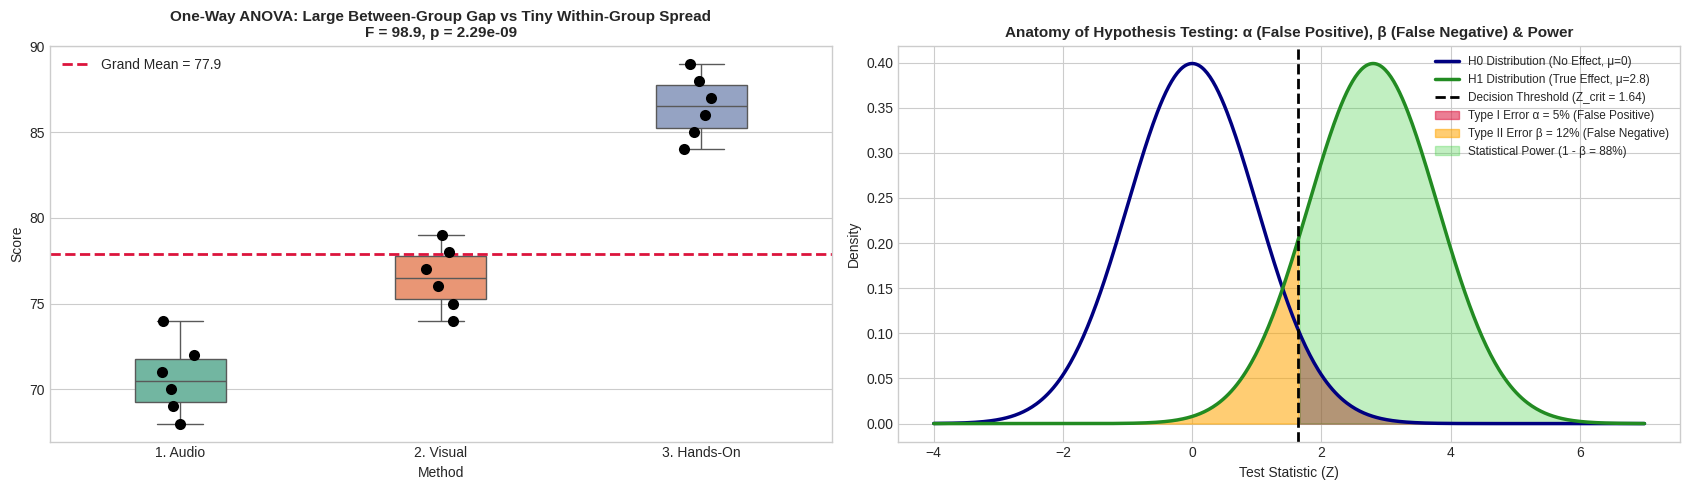

In [7]:
# ==============================================================================
# MODULE 0 (LEVEL 3B): THE 4 CLASSICAL HYPOTHESIS TESTS IN ACTION
# ==============================================================================
# 1. TWO-SAMPLE WELCH'S t-TEST (Comparing 2 Groups: Fertilizer A vs Fertilizer B crop yield)
fert_A = np.array([20.1, 21.5, 19.8, 22.0, 20.5, 21.2, 19.9, 20.8])
fert_B = np.array([23.4, 24.1, 22.8, 25.0, 23.9, 24.5, 22.9, 23.8])

t_stat, p_val_t = stats.ttest_ind(fert_B, fert_A, equal_var=False)  # Welch's t-test
print("[1. TWO-SAMPLE WELCH'S t-TEST: Fertilizer A vs Fertilizer B]")
print(f"  Mean A = {fert_A.mean():.2f}, Mean B = {fert_B.mean():.2f} (Diff = +{fert_B.mean()-fert_A.mean():.2f})")
print(f"  t-statistic = {t_stat:.4f}, p-value = {p_val_t:.4e} -> {'REJECT H0 (Significant!)' if p_val_t < 0.05 else 'Fail to Reject H0'}\n")

# 2. PAIRED t-TEST (Same 6 students' test scores BEFORE vs AFTER a tutoring session)
# Notice: Student-to-student baseline ability varies hugely (50 to 90), which would mask the +4 point gain in an unpaired test!
before_scores = np.array([52, 65, 70, 78, 85, 91])
after_scores  = np.array([56, 68, 75, 81, 90, 95])  # Every student improved by +3 to +5 points!

t_unpaired, p_unpaired = stats.ttest_ind(after_scores, before_scores)
t_paired, p_paired = stats.ttest_rel(after_scores, before_scores)
print("[2. PAIRED vs UNPAIRED t-TEST: Same 6 Students Before vs After Tutoring]")
print(f"  Wrong Unpaired t-test (ignores that it's the same students): t = {t_unpaired:.3f}, p = {p_unpaired:.4f} (Misses the effect!)")
print(f"  Correct Paired t-test (tests individual gains d_i = +4.0)  : t = {t_paired:.3f}, p = {p_paired:.4e} (Highly Significant!)\n")

# 3. ONE-WAY ANOVA F-TEST (Comparing 3 Teaching Methods: Audio, Visual, Hands-On)
method_audio    = np.array([70, 72, 68, 74, 71, 69])
method_visual   = np.array([75, 78, 74, 79, 76, 77])
method_handson  = np.array([85, 88, 84, 89, 86, 87])

f_stat, p_val_anova = stats.f_oneway(method_audio, method_visual, method_handson)
print("[3. ONE-WAY ANOVA (F-TEST): Comparing 3 Teaching Methods]")
print(f"  Group Means: Audio={method_audio.mean():.1f}, Visual={method_visual.mean():.1f}, Hands-On={method_handson.mean():.1f}")
print(f"  F-statistic (Between-Group Var / Within-Group Var) = {f_stat:.2f}, p-value = {p_val_anova:.4e}\n")

# 4. CHI-SQUARE TEST OF INDEPENDENCE (Categorical Contingency Table: Shift Day/Night vs Defective Part Yes/No)
# Rows: [Day Shift, Night Shift], Columns: [Pass, Defective]
contingency_table = np.array([
    [480, 20],  # Day shift:   480 Pass, 20 Defective (4% defect rate)
    [440, 60]   # Night shift: 440 Pass, 60 Defective (12% defect rate)
])
chi2_stat, p_val_chi2, dof, expected_counts = stats.chi2_contingency(contingency_table, correction=False)
print("[4. CHI-SQUARE TEST OF INDEPENDENCE: Factory Shift vs Defect Rate]")
print(f"  Observed Counts:\n{contingency_table}")
print(f"  Expected Counts if Shift & Defects Were Independent:\n{expected_counts}")
print(f"  Chi2-statistic = {chi2_stat:.4f}, p-value = {p_val_chi2:.4e}\n")

# Visualize ANOVA Signal-to-Noise (Between-Group vs Within-Group Variance) & Type I/II Error Tradeoff
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# Left: ANOVA Visualization
anova_df = pd.DataFrame({
    "Score": np.concatenate([method_audio, method_visual, method_handson]),
    "Method": ["1. Audio"]*6 + ["2. Visual"]*6 + ["3. Hands-On"]*6
})
sns.boxplot(data=anova_df, x="Method", y="Score", ax=axes[0], width=0.35, palette="Set2")
sns.stripplot(data=anova_df, x="Method", y="Score", ax=axes[0], color="black", size=8, jitter=0.08)
axes[0].axhline(anova_df["Score"].mean(), color="crimson", ls="--", lw=2, label=f"Grand Mean = {anova_df['Score'].mean():.1f}")
axes[0].set_title(f"One-Way ANOVA: Large Between-Group Gap vs Tiny Within-Group Spread\nF = {f_stat:.1f}, p = {p_val_anova:.2e}", fontsize=11, fontweight="bold")
axes[0].legend()

# Right: Visualizing Type I Error (Alpha), Type II Error (Beta), and Statistical Power (1 - Beta)
x_null = np.linspace(-4, 7, 500)
pdf_h0 = stats.norm.pdf(x_null, loc=0, scale=1)    # Null Hypothesis H0: mu = 0
pdf_h1 = stats.norm.pdf(x_null, loc=2.8, scale=1)  # Alternative H1: True effect size = 2.8 SEs
crit_z = stats.norm.ppf(0.95)                      # One-sided alpha = 0.05 threshold (Z = 1.645)

axes[1].plot(x_null, pdf_h0, color="navy", lw=2.5, label="H0 Distribution (No Effect, μ=0)")
axes[1].plot(x_null, pdf_h1, color="forestgreen", lw=2.5, label="H1 Distribution (True Effect, μ=2.8)")
axes[1].axvline(crit_z, color="black", ls="--", lw=2, label=f"Decision Threshold (Z_crit = {crit_z:.2f})")

axes[1].fill_between(x_null, pdf_h0, where=(x_null >= crit_z), color="crimson", alpha=0.55, label="Type I Error α = 5% (False Positive)")
axes[1].fill_between(x_null, pdf_h1, where=(x_null < crit_z), color="orange", alpha=0.55, label="Type II Error β = 12% (False Negative)")
axes[1].fill_between(x_null, pdf_h1, where=(x_null >= crit_z), color="limegreen", alpha=0.30, label="Statistical Power (1 - β = 88%)")

axes[1].set_title("Anatomy of Hypothesis Testing: α (False Positive), β (False Negative) & Power", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Test Statistic (Z)")
axes[1].set_ylabel("Density")
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

---

## Level 3C: Simple Linear Regression (Ordinary Least Squares — OLS)

Hypothesis tests compare group averages. What if both our input $X$ (e.g., Hours Studied) and our output $Y$ (e.g., Exam Score) are continuous numbers, and we want to predict $Y$ from $X$?

### 1. The Simple Linear Regression Equation
We model $Y$ as a straight line plus random Gaussian noise $\epsilon_i \sim \mathcal{N}(0, \sigma^2)$:
$$Y_i = \beta_0 + \beta_1 X_i + \epsilon_i$$
* **$\beta_0$ (Intercept):** Predicted value of $Y$ when $X = 0$.
* **$\beta_1$ (Slope):** How much $Y$ changes on average when we increase $X$ by **$1$ unit**.

---

### 2. How Does "Ordinary Least Squares" (OLS) Find the Best Line?
For any candidate line $\hat{y}_i = \hat{\beta}_0 + \hat{\beta}_1 x_i$, the vertical prediction error (called the **Residual**) for point $i$ is:
$$e_i = y_i - \hat{y}_i = y_i - (\hat{\beta}_0 + \hat{\beta}_1 x_i)$$

OLS chooses $\hat{\beta}_0$ and $\hat{\beta}_1$ to minimize the **Residual Sum of Squares ($\text{RSS}$)**:
$$\text{RSS} = \sum_{i=1}^{n} e_i^2 = \sum_{i=1}^{n} (y_i - \hat{\beta}_0 - \hat{\beta}_1 x_i)^2$$

Taking partial derivatives with respect to $\hat{\beta}_0$ and $\hat{\beta}_1$ and setting them to zero yields two beautiful closed-form formulas that connect directly back to Level 1 & Level 2:
$$\hat{\beta}_1 = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^n (x_i - \bar{x})^2} = \frac{\text{Cov}(X, Y)}{\text{Var}(X)} = r_{X,Y} \cdot \left(\frac{s_Y}{s_X}\right)$$
$$\hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$$
* **Look at $\hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$:** Rearranging gives $\bar{y} = \hat{\beta}_0 + \hat{\beta}_1 \bar{x}$. This proves a classic interview fact: **An OLS regression line ALWAYS passes through the exact center of gravity $(\bar{x}, \bar{y})$ of the data!**
* **Look at $\hat{\beta}_1 = r_{X,Y} (s_Y / s_X)$:** The slope is simply the Pearson correlation $r$ scaled by the ratio of standard deviations!

---

### 3. Decomposing Variance: TSS = ESS + RSS and $R^2$ (Coefficient of Determination)
How good is our line compared to just guessing the flat average $\bar{y}$ for everyone?
1. **Total Sum of Squares ($\text{TSS} = \sum(y_i - \bar{y})^2$):** Total variance in $Y$ before using $X$.
2. **Residual Sum of Squares ($\text{RSS} = \sum(y_i - \hat{y}_i)^2$):** Unexplained error remaining *after* fitting the line.
3. **Explained Sum of Squares ($\text{ESS} = \sum(\hat{y}_i - \bar{y})^2$):** Variance explained by our regression line.

Because $\text{TSS} = \text{ESS} + \text{RSS}$, the **fraction of total variance in $Y$ explained by $X$** is **$R^2$**:
$$R^2 = 1 - \frac{\text{RSS}}{\text{TSS}} = \frac{\text{ESS}}{\text{TSS}} \in [0, 1]$$
*(In Simple Linear Regression with 1 feature, $R^2$ is literally equal to the square of Pearson correlation: $R^2 = r_{X,Y}^2$!)*

---

### 4. Confidence Interval vs. Prediction Interval Around a Regression Line
When you plot shaded bands around a regression line, there are **two completely different bands** (a favorite Senior DS interview question!):
* **95% Confidence Interval (Narrow Inner Band):** Uncertainty about where the **true average line** $\mathbb{E}[Y \mid X = x^*] = \beta_0 + \beta_1 x^*$ lies:
  $$\text{SE}_{\text{mean}}(x^*) = \hat{\sigma}\sqrt{\frac{1}{n} + \frac{(x^* - \bar{x})^2}{\sum(x_i - \bar{x})^2}}$$
  *(Notice: It is narrowest at the center $\bar{x}$ and flares out into a bowtie shape at the edges!)*
* **95% Prediction Interval (Wide Outer Band):** Uncertainty about where a **single new individual observation** $y_{\text{new}} = \beta_0 + \beta_1 x^* + \epsilon_{\text{new}}$ will land. Because an individual point includes irreducible noise $\epsilon_{\text{new}} \sim \mathcal{N}(0, \sigma^2)$, there is an extra $1 +$ inside the square root:
  $$\text{SE}_{\text{pred}}(x^*) = \hat{\sigma}\sqrt{\mathbf{1} + \frac{1}{n} + \frac{(x^* - \bar{x})^2}{\sum(x_i - \bar{x})^2}}$$

[OLS SIMPLE LINEAR REGRESSION: HAND FORMULAS vs STATSMODELS]
  Intercept (beta_0) : Hand = 44.4314 | statsmodels = 44.4314
  Slope (beta_1)     : Hand = 4.0541 | statsmodels = 4.0541
  Slope SE & t-stat  : SE = 0.2869, t = 14.1295 (p = 3.4901e-11)
  R-Squared (1-RSS/TSS): 0.9173 | Pearson r^2 = 0.9173



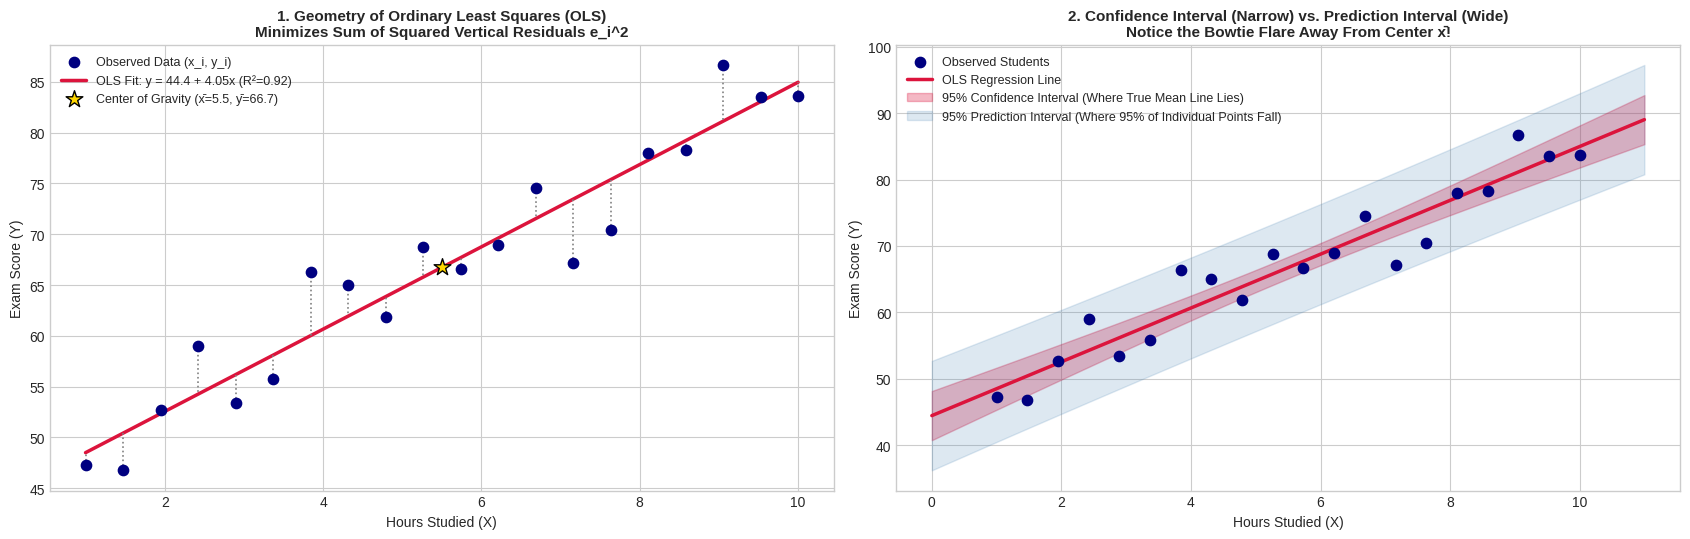

In [8]:
# ==============================================================================
# MODULE 0 (LEVEL 3C): OLS REGRESSION FROM SCRATCH, R^2 & CI vs PI BANDS
# ==============================================================================
import statsmodels.api as sm

np.random.seed(42)
# Toy Example: Hours Studied (X) vs Exam Score (Y) for n = 20 students
x_hours = np.linspace(1, 10, 20)
true_b0, true_b1 = 40.0, 5.0
y_score = true_b0 + true_b1 * x_hours + np.random.normal(0, 4.5, size=len(x_hours))

# 1. Compute OLS Closed-Form Formulas By Hand (Using Covariance & Variance)
x_bar, y_bar = np.mean(x_hours), np.mean(y_score)
cov_xy = np.sum((x_hours - x_bar) * (y_score - y_bar)) / (len(x_hours) - 1)
var_x  = np.sum((x_hours - x_bar) ** 2) / (len(x_hours) - 1)

b1_hand = cov_xy / var_x
b0_hand = y_bar - b1_hand * x_bar

# Predictions, Residuals, TSS, RSS, R^2, and slope t-statistic
y_hat = b0_hand + b1_hand * x_hours
residuals = y_score - y_hat
tss = np.sum((y_score - y_bar) ** 2)
rss = np.sum(residuals ** 2)
r_squared = 1.0 - (rss / tss)
r_pearson, _ = stats.pearsonr(x_hours, y_score)

# Residual Standard Error (dividing by n - 2 because we estimated 2 parameters: b0 and b1!)
n = len(x_hours)
s_err = np.sqrt(rss / (n - 2))
se_b1 = s_err / np.sqrt(np.sum((x_hours - x_bar) ** 2))
t_stat_b1 = b1_hand / se_b1
p_val_b1 = 2 * (1 - stats.t.cdf( abs(t_stat_b1), df=n - 2 ))

# 2. Verify Against Production statsmodels.OLS
X_sm = sm.add_constant(x_hours)
ols_model = sm.OLS(y_score, X_sm).fit()

print("[OLS SIMPLE LINEAR REGRESSION: HAND FORMULAS vs STATSMODELS]")
print(f"  Intercept (beta_0) : Hand = {b0_hand:.4f} | statsmodels = {ols_model.params[0]:.4f}")
print(f"  Slope (beta_1)     : Hand = {b1_hand:.4f} | statsmodels = {ols_model.params[1]:.4f}")
print(f"  Slope SE & t-stat  : SE = {se_b1:.4f}, t = {t_stat_b1:.4f} (p = {p_val_b1:.4e})")
print(f"  R-Squared (1-RSS/TSS): {r_squared:.4f} | Pearson r^2 = {r_pearson**2:.4f}\n")

# 3. Plot OLS Line, Residuals, Center of Gravity, Confidence Interval & Prediction Interval
x_grid = np.linspace(0, 11, 200)
pred_summary = ols_model.get_prediction(sm.add_constant(x_grid)).summary_frame(alpha=0.05)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

# Left Plot: The Geometry of Least Squares (Residuals & Center of Gravity)
axes[0].scatter(x_hours, y_score, color="navy", s=55, zorder=4, label="Observed Data (x_i, y_i)")
axes[0].plot(x_hours, y_hat, color="crimson", lw=2.5, label=f"OLS Fit: y = {b0_hand:.1f} + {b1_hand:.2f}x (R²={r_squared:.2f})")
for xi, yi, yhi in zip(x_hours, y_score, y_hat):
    axes[0].plot([xi, xi], [yi, yhi], color="gray", ls=":", lw=1.2)
axes[0].scatter([x_bar], [y_bar], color="gold", edgecolor="black", s=160, marker="*", zorder=5,
                label=f"Center of Gravity (x̄={x_bar:.1f}, ȳ={y_bar:.1f})")
axes[0].set_title("1. Geometry of Ordinary Least Squares (OLS)\nMinimizes Sum of Squared Vertical Residuals e_i^2", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Hours Studied (X)")
axes[0].set_ylabel("Exam Score (Y)")
axes[0].legend(loc="upper left", fontsize=9)

# Right Plot: 95% Confidence Interval (Mean Line) vs 95% Prediction Interval (New Individual Point)
axes[1].scatter(x_hours, y_score, color="navy", s=55, zorder=4, label="Observed Students")
axes[1].plot(x_grid, pred_summary["mean"], color="crimson", lw=2.5, label="OLS Regression Line")
axes[1].fill_between(x_grid, pred_summary["mean_ci_lower"], pred_summary["mean_ci_upper"],
                     color="crimson", alpha=0.30, label="95% Confidence Interval (Where True Mean Line Lies)")
axes[1].fill_between(x_grid, pred_summary["obs_ci_lower"], pred_summary["obs_ci_upper"],
                     color="steelblue", alpha=0.18, label="95% Prediction Interval (Where 95% of Individual Points Fall)")
axes[1].set_title("2. Confidence Interval (Narrow) vs. Prediction Interval (Wide)\nNotice the Bowtie Flare Away From Center x̄!", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Hours Studied (X)")
axes[1].set_ylabel("Exam Score (Y)")
axes[1].legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

---

# Module 0 — Level 4: Graduate / Senior Data Scientist Statistical Theory

## Level 4A: Point Estimation Theory — What Makes an Estimator "Good"?

Suppose nature has a hidden true parameter $\theta$ (e.g., the true failure rate of a valve, or the true maximum speed of a tank), and we build a formula $\hat{\theta}(X_1, \dots, X_n)$ to estimate it from a sample of size $n$. Because the sample is random, **$\hat{\theta}$ is itself a random variable**!

### 1. Bias, Variance, and the Mean Squared Error (MSE) Decomposition
How close is our estimator $\hat{\theta}$ to the true $\theta$ on average? We measure its **Mean Squared Error ($\text{MSE}$)**:
$$\text{MSE}(\hat{\theta}) = \mathbb{E}\left[(\hat{\theta} - \theta)^2\right]$$

By adding and subtracting $\mathbb{E}[\hat{\theta}]$ inside the square, we get the most famous identity in Statistical Learning:
$$\text{MSE}(\hat{\theta}) = \underbrace{\left(\mathbb{E}[\hat{\theta}] - \theta\right)^2}_{\text{Bias}(\hat{\theta})^2} + \underbrace{\mathbb{E}\left[\left(\hat{\theta} - \mathbb{E}[\hat{\theta}]\right)^2\right]}_{\text{Var}(\hat{\theta})}$$

* **Bias ($\mathbb{E}[\hat{\theta}] - \theta$):** Systematic bullseye shift. If $\text{Bias} = 0$, the estimator is **Unbiased** ($\mathbb{E}[\hat{\theta}] = \theta$).
* **Variance ($\text{Var}(\hat{\theta})$):** How wildly $\hat{\theta}$ scatters from sample to sample.
* **Consistency ($\hat{\theta}_n \xrightarrow{p} \theta$):** As sample size $n \to \infty$, both Bias $\to 0$ and Variance $\to 0$, so the estimator collapses onto the true $\theta$.
* **Senior DS Nuance:** An unbiased estimator is **not always best**! Sometimes introducing a tiny amount of Bias shrinks the Variance so drastically that total $\text{MSE} = \text{Bias}^2 + \text{Variance}$ becomes much smaller (this is the entire foundation of **Ridge / Lasso Regularization** and **James-Stein Shrinkage**!).

---

### 2. Fisher Information & The Cramér-Rao Lower Bound (CRLB)
If we restrict ourselves to **Unbiased Estimators** ($\text{Bias} = 0$), how small can the variance $\text{Var}(\hat{\theta})$ possibly get? Is there a fundamental "speed limit" in nature on how accurately you can estimate $\theta$ from $n$ data points?

**Yes!** The **Cramér-Rao Inequality** states that for any unbiased estimator $\hat{\theta}$:
$$\text{Var}(\hat{\theta}) \ge \frac{1}{I_n(\theta)} = \frac{1}{n \cdot I_1(\theta)}$$
where $I_1(\theta)$ is the **Fisher Information** of a single observation—measuring how sharply the log-likelihood $\ln f(X; \theta)$ curves around the true $\theta$:
$$I_1(\theta) = \mathbb{E}\left[ \left(\frac{\partial}{\partial \theta} \ln f(X; \theta)\right)^2 \right] = -\mathbb{E}\left[ \frac{\partial^2}{\partial \theta^2} \ln f(X; \theta) \right]$$
* **Intuition:** If the log-likelihood peak is **razor-sharp** (high curvature / large negative second derivative), Fisher Information $I(\theta)$ is huge, so $\text{Var}(\hat{\theta})$ is tiny! If the log-likelihood is **flat**, changing $\theta$ barely changes the data probability, so $I(\theta)$ is tiny and no estimator on earth can pin down $\theta$ accurately.
* Any unbiased estimator that hits the exact Cramér-Rao Lower Bound is called **Minimum Variance Unbiased Estimator (MVUE / Efficient)**.

---

### 3. Method of Moments (MoM) vs. Maximum Likelihood Estimation (MLE)
How do we invent an estimator formula $\hat{\theta}$ in the first place?
> **Classic Interview Problem (The "German Tank Problem"):**
> Suppose enemy tanks are numbered sequentially from $1$ to $\theta$, which we can model continuously as $X_1, \dots, X_n \stackrel{\text{i.i.d.}}{\sim} \text{Uniform}(0, \theta)$. We observe $n = 5$ tanks with numbers: $[12, \, 45, \, 31, \, 70, \, 52]$. **What is the true maximum number $\theta$?**

1. **Method of Moments (MoM):** Set the theoretical mean $\mathbb{E}[X] = \frac{\theta}{2}$ equal to the sample mean $\bar{X}$:
   $$\frac{\hat{\theta}_{\text{MoM}}}{2} = \bar{X} \implies \hat{\theta}_{\text{MoM}} = 2\bar{X}$$
   * For our 5 tanks, $\bar{X} = 42.0 \implies \hat{\theta}_{\text{MoM}} = 2(42) = \mathbf{84}$.
   * *Wait—what if our 5 tanks were $[1, 2, 3, 4, 90]$?* Then $\bar{X} = 20 \implies \hat{\theta}_{\text{MoM}} = \mathbf{40}$—which is **impossible** because we literally saw tank $\#90$ with our own eyes!
2. **Maximum Likelihood Estimation (MLE):** Pick $\theta$ that maximizes the joint density $L(\theta) = \prod_{i=1}^n \frac{1}{\theta} = \frac{1}{\theta^n}$ subject to $\theta \ge \max(X_1, \dots, X_n)$:
   $$\hat{\theta}_{\text{MLE}} = \max(X_1, \dots, X_n) = X_{(n)}$$
   * Notice that the maximum of $n$ samples is always slightly less than $\theta$: $\mathbb{E}[X_{(n)}] = \frac{n}{n+1}\theta$ (so $\hat{\theta}_{\text{MLE}}$ is slightly **biased downward**!).
3. **Bias-Corrected MLE (The MVUE):** Multiply by $\frac{n+1}{n}$ to remove the bias:
   $$\hat{\theta}_{\text{MVUE}} = \frac{n + 1}{n} \max(X_1, \dots, X_n)$$
   As we will prove in code below, $\hat{\theta}_{\text{MLE}}$ and $\hat{\theta}_{\text{MVUE}}$ crush Method of Moments by an order of magnitude in MSE!

[GERMAN TANK PROBLEM: ESTIMATING TRUE THETA = 100.0 WITH SAMPLE SIZE n = 10]


,Mean E[theta_hat],Bias,Bias^2,Variance,Total MSE (Bias^2 + Var)
Estimator,,,,,
1. Method of Moments (2 * X_bar),100.057,0.057,0.003,332.996,332.993
2. Raw MLE (max(X_i)) [Biased],90.925,-9.075,82.360,68.233,150.592
3. Bias-Corrected MLE ((n+1)/n * max(X_i)) [MVUE],100.017,0.017,0.000,82.562,82.561


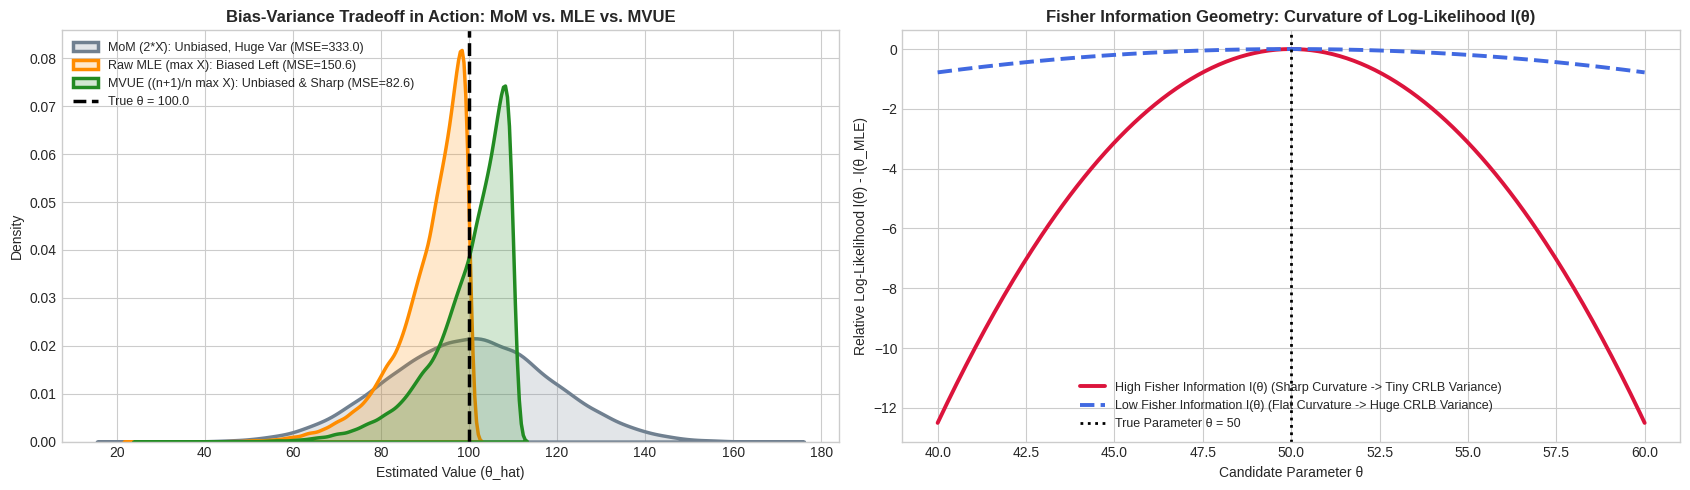

In [9]:
# ==============================================================================
# MODULE 0 (LEVEL 4A): ESTIMATOR BIAS-VARIANCE-MSE SHOWDOWN & CRAMER-RAO BOUND
# ==============================================================================
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)

# 1. The German Tank Problem: Uniform(0, theta) where true_theta = 100.0
true_theta = 100.0
n_samples = 10
n_sims = 50_000

# Draw (50,000 x 10) matrix of Uniform(0, 100) observations
draws = np.random.uniform(0, true_theta, size=(n_sims, n_samples))

# Three competing estimators for theta:
est_mom  = 2.0 * np.mean(draws, axis=1)                        # 1. Method of Moments: 2 * X_bar
est_mle  = np.max(draws, axis=1)                               # 2. Biased MLE: max(X)
est_mvue = ((n_samples + 1) / n_samples) * np.max(draws, axis=1) # 3. Unbiased MVUE: (n+1)/n * max(X)

def evaluate_estimator(est: np.ndarray, target: float, name: str) -> dict:
    bias = np.mean(est) - target
    var  = np.var(est, ddof=1)
    mse  = np.mean((est - target) ** 2)
    return {
        "Estimator": name,
        "Mean E[theta_hat]": np.mean(est),
        "Bias": bias,
        "Bias^2": bias ** 2,
        "Variance": var,
        "Total MSE (Bias^2 + Var)": mse
    }

est_df = pd.DataFrame([
    evaluate_estimator(est_mom,  true_theta, "1. Method of Moments (2 * X_bar)"),
    evaluate_estimator(est_mle,  true_theta, "2. Raw MLE (max(X_i)) [Biased]"),
    evaluate_estimator(est_mvue, true_theta, "3. Bias-Corrected MLE ((n+1)/n * max(X_i)) [MVUE]")
]).set_index("Estimator")

print(f"[GERMAN TANK PROBLEM: ESTIMATING TRUE THETA = {true_theta} WITH SAMPLE SIZE n = {n_samples}]")
display(est_df.round(3))

# 2. Visualizing the Sampling Distributions of the 3 Estimators + Cramér-Rao Curvature Intuition
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# Left Plot: Sampling distributions of MoM vs MLE vs MVUE
sns.kdeplot(est_mom,  ax=axes[0], color="slategray", lw=2.5, fill=True, alpha=0.2, label=f"MoM (2*X̄): Unbiased, Huge Var (MSE={est_df.iloc[0,4]:.1f})")
sns.kdeplot(est_mle,  ax=axes[0], color="darkorange", lw=2.5, fill=True, alpha=0.2, label=f"Raw MLE (max X): Biased Left (MSE={est_df.iloc[1,4]:.1f})")
sns.kdeplot(est_mvue, ax=axes[0], color="forestgreen", lw=2.5, fill=True, alpha=0.2, label=f"MVUE ((n+1)/n max X): Unbiased & Sharp (MSE={est_df.iloc[2,4]:.1f})")
axes[0].axvline(true_theta, color="black", ls="--", lw=2.5, label="True θ = 100.0")
axes[0].set_title("Bias-Variance Tradeoff in Action: MoM vs. MLE vs. MVUE", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Estimated Value (θ_hat)")
axes[0].set_ylabel("Density")
axes[0].legend(loc="upper left", fontsize=9)

# Right Plot: Fisher Information & Cramér-Rao Bound Intuition (Sharp vs Flat Log-Likelihood)
theta_grid = np.linspace(40, 60, 300)
# High Fisher Info (low noise sigma=2) vs Low Fisher Info (high noise sigma=8) around true_mu = 50
ll_high_info = -0.5 * ((theta_grid - 50.0) / 2.0) ** 2
ll_low_info  = -0.5 * ((theta_grid - 50.0) / 8.0) ** 2

axes[1].plot(theta_grid, ll_high_info, color="crimson", lw=2.8, label="High Fisher Information I(θ) (Sharp Curvature -> Tiny CRLB Variance)")
axes[1].plot(theta_grid, ll_low_info, color="royalblue", lw=2.8, ls="--", label="Low Fisher Information I(θ) (Flat Curvature -> Huge CRLB Variance)")
axes[1].axvline(50.0, color="black", ls=":", lw=2, label="True Parameter θ = 50")
axes[1].set_title("Fisher Information Geometry: Curvature of Log-Likelihood l(θ)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Candidate Parameter θ")
axes[1].set_ylabel("Relative Log-Likelihood l(θ) - l(θ_MLE)")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

---

## Level 4B: Computational Inference — Bootstrapping & Permutation Testing

In Level 3, we used formulas like $\bar{x} \pm t \cdot \frac{s}{\sqrt{n}}$ to get a Confidence Interval for the **Mean**.
> **But what if your VP asks for a 95% Confidence Interval for the MEDIAN, or the 90th Percentile ($P_{90}$), or the Ratio of two Medians, or an ML model's $F_1$-score?**
> There is **no simple closed-form formula** $\frac{s}{\sqrt{n}}$ for those!

In 1979, Stanford statistician **Bradley Efron** invented the **Non-Parametric Bootstrap**, replacing pages of calculus with raw computer power:

### 1. The Non-Parametric Bootstrap (Sampling *With Replacement*)
* **Core Idea:** We cannot afford to go back into the real world and collect $10,000$ new samples of size $n$ from the true population $F$. However, our original sample $X = \{x_1, \dots, x_n\}$ is already a miniature approximation of the population (the Empirical CDF $\hat{F}_n$)!
* **The Algorithm:**
  1. From your original sample of size $n$, draw $n$ items **WITH REPLACEMENT** to form a "Bootstrap Resample" $X^{*(b)} = \{x_1^*, \dots, x_n^*\}$. *(Because we sample with replacement, some original points appear twice or thrice in $X^{*(b)}$, and roughly $1 - (1 - 1/n)^n \approx e^{-1} \approx 36.8\%$ of points are left out—which is where "Out-of-Bag" error in Random Forests comes from!)*
  2. Compute your desired statistic $\hat{\theta}^{*(b)}$ (e.g., Median, 90th Percentile, $R^2$) on that resample.
  3. Repeat $B = 10,000$ times and take the **$2.5\text{th}$ and $97.5\text{th}$ percentiles** of $\{\hat{\theta}^{*(1)}, \dots, \hat{\theta}^{*(B)}\}$ to get the **95% Percentile Bootstrap Confidence Interval**!

---

### 2. The Exact Permutation Test (Sampling *Without Replacement* to Test $H_0$)
What if you want to test whether Group A ($n_A$ points) and Group B ($n_B$ points) are significantly different on a heavily skewed metric where a $t$-test is invalid?
* **Under the Null Hypothesis ($H_0$):** Group A and Group B come from the **exact same distribution**—meaning the labels `"Group A"` and `"Group B"` are completely arbitrary sticky notes!
* **The Algorithm:**
  1. Compute the observed difference in your metric: $\Delta_{\text{obs}} = |\text{Stat}(A) - \text{Stat}(B)|$.
  2. Pool all $N = n_A + n_B$ numbers into a single bucket, **shuffle the labels randomly (without replacement)**, split back into a fake Group A ($n_A$) and fake Group B ($n_B$), and compute $\Delta^{*(b)}$.
  3. Repeat $B = 10,000$ times. Your **exact non-parametric $p$-value** is simply the fraction of shuffled worlds where the fake difference beat your real difference:
     $$p_{\text{perm}} = \frac{1 + \sum_{b=1}^{B} \mathbb{I}\left(|\Delta^{*(b)}| \ge |\Delta_{\text{obs}}|\right)}{B + 1}$$

[1. NON-PARAMETRIC BOOTSTRAP (10,000 RESAMPLES WITH REPLACEMENT)]
  Observed Sample Median : 41.46 ms | 95% Bootstrap CI: [32.12, 55.93] ms
  Observed Sample P90    : 103.05 ms | 95% Bootstrap CI: [68.22, 176.87] ms

[2. EXACT PERMUTATION TEST OF MEDIAN DIFFERENCE ON SKEWED DATA]
  Observed Difference in Medians (Treatment - Control): +13.76
  Permutation Test p-value (10,000 shuffles)          : p = 0.2146
  Mann-Whitney U Non-Parametric Rank Test p-value     : p = 0.1352


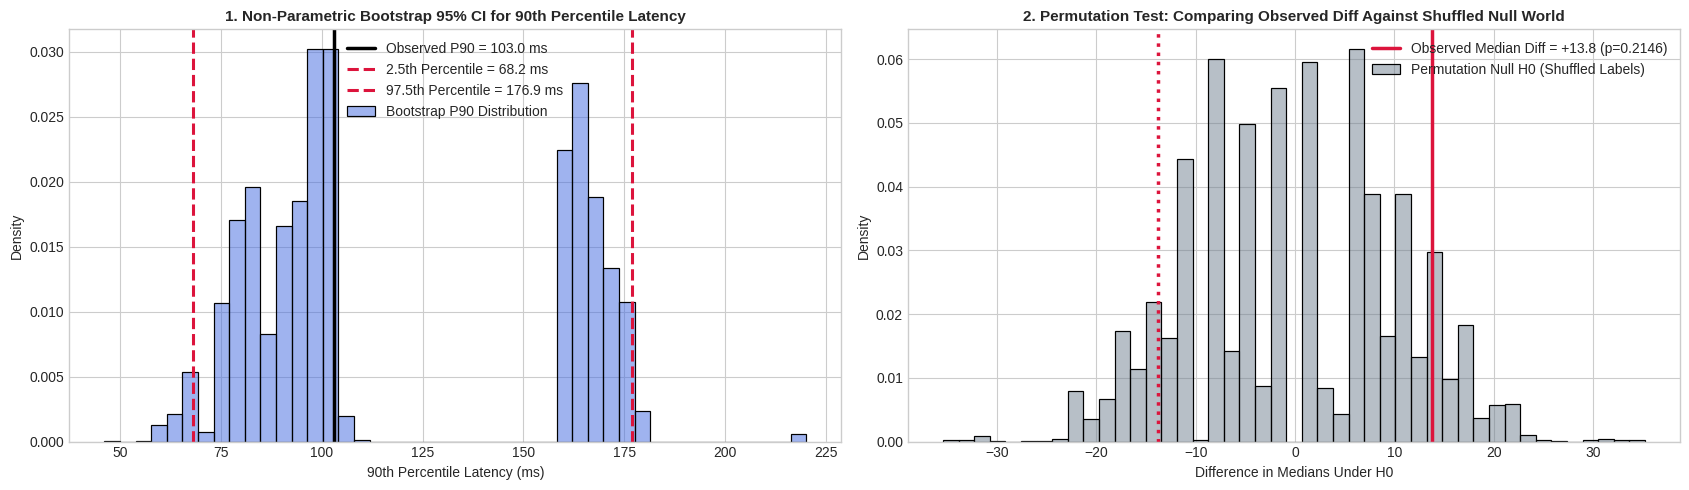

In [10]:
# ==============================================================================
# MODULE 0 (LEVEL 4B): VECTORIZED BOOTSTRAP CI & PERMUTATION TEST FROM SCRATCH
# ==============================================================================
np.random.seed(42)

# Suppose we measure server latency (ms) on 40 requests — heavily right-skewed (Log-Normal)!
latencies = stats.lognorm.rvs(s=0.8, scale=50.0, size=40)
obs_median = np.median(latencies)
obs_p90    = np.percentile(latencies, 90)

# 1. Vectorized Non-Parametric Bootstrap (B = 10,000 resamples in 2 lines of NumPy!)
B = 10_000
n = len(latencies)
# Generate (B x n) random integer indices in [0, n-1] WITH replacement
boot_indices = np.random.randint(0, n, size=(B, n))
boot_samples = latencies[boot_indices]

boot_medians = np.median(boot_samples, axis=1)
boot_p90s    = np.percentile(boot_samples, 90, axis=1)

ci_median = np.percentile(boot_medians, [2.5, 97.5])
ci_p90    = np.percentile(boot_p90s, [2.5, 97.5])

print("[1. NON-PARAMETRIC BOOTSTRAP (10,000 RESAMPLES WITH REPLACEMENT)]")
print(f"  Observed Sample Median : {obs_median:.2f} ms | 95% Bootstrap CI: [{ci_median[0]:.2f}, {ci_median[1]:.2f}] ms")
print(f"  Observed Sample P90    : {obs_p90:.2f} ms | 95% Bootstrap CI: [{ci_p90[0]:.2f}, {ci_p90[1]:.2f}] ms\n")

# 2. Permutation Test vs Mann-Whitney U vs t-Test on Skewed Data with an Outlier
group_control   = stats.expon.rvs(scale=20.0, size=25)
group_treatment = stats.expon.rvs(scale=35.0, size=25)

obs_diff_medians = np.median(group_treatment) - np.median(group_control)
pooled = np.concatenate([group_control, group_treatment])
n_c = len(group_control)

# Shuffle pooled array 10,000 times WITHOUT replacement to simulate H0 (labels don't matter)
perm_diffs = np.empty(B)
for b in range(B):
    shuffled = np.random.permutation(pooled)
    perm_diffs[b] = np.median(shuffled[n_c:]) - np.median(shuffled[:n_c])

p_val_perm = (1 + np.sum(np.abs(perm_diffs) >= np.abs(obs_diff_medians))) / (B + 1)
u_stat, p_val_mwu = stats.mannwhitneyu(group_treatment, group_control, alternative="two-sided")

print("[2. EXACT PERMUTATION TEST OF MEDIAN DIFFERENCE ON SKEWED DATA]")
print(f"  Observed Difference in Medians (Treatment - Control): +{obs_diff_medians:.2f}")
print(f"  Permutation Test p-value (10,000 shuffles)          : p = {p_val_perm:.4f}")
print(f"  Mann-Whitney U Non-Parametric Rank Test p-value     : p = {p_val_mwu:.4f}")

# Visualize Bootstrap Distribution & Permutation Null Distribution
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

sns.histplot(boot_p90s, stat="density", bins=45, ax=axes[0], color="royalblue", alpha=0.5, label="Bootstrap P90 Distribution")
axes[0].axvline(obs_p90, color="black", lw=2.5, label=f"Observed P90 = {obs_p90:.1f} ms")
axes[0].axvline(ci_p90[0], color="crimson", ls="--", lw=2.2, label=f"2.5th Percentile = {ci_p90[0]:.1f} ms")
axes[0].axvline(ci_p90[1], color="crimson", ls="--", lw=2.2, label=f"97.5th Percentile = {ci_p90[1]:.1f} ms")
axes[0].set_title("1. Non-Parametric Bootstrap 95% CI for 90th Percentile Latency", fontsize=11, fontweight="bold")
axes[0].set_xlabel("90th Percentile Latency (ms)")
axes[0].legend()

sns.histplot(perm_diffs, stat="density", bins=45, ax=axes[1], color="slategray", alpha=0.5, label="Permutation Null H0 (Shuffled Labels)")
axes[1].axvline(obs_diff_medians, color="crimson", lw=2.5, label=f"Observed Median Diff = +{obs_diff_medians:.1f} (p={p_val_perm:.4f})")
axes[1].axvline(-obs_diff_medians, color="crimson", lw=2.5, ls=":")
axes[1].set_title("2. Permutation Test: Comparing Observed Diff Against Shuffled Null World", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Difference in Medians Under H0")
axes[1].legend()

plt.tight_layout()
plt.show()

---

## Level 4C: Bayesian Inference, Information Theory & The Multiple Testing Crisis

### 1. Frequentist vs. Bayesian Philosophy & Conjugate Updating
* **Frequentist:** The parameter $\theta$ is a **fixed unknown constant**. Data $D$ is random.
* **Bayesian:** The parameter $\theta$ is treated as a **Random Variable** with a probability distribution representing our degree of belief! As new data $D$ arrives, we update our **Prior $p(\theta)$** into a **Posterior $p(\theta \mid D)$** using Bayes' Rule:
  $$\underbrace{p(\theta \mid D)}_{\text{Posterior}} = \frac{\overbrace{p(D \mid \theta)}^{\text{Likelihood}} \cdot \overbrace{p(\theta)}^{\text{Prior}}}{\underbrace{\int p(D \mid \theta')p(\theta')\,d\theta'}_{\text{Marginal Likelihood / Evidence } p(D)}} \propto \text{Likelihood} \times \text{Prior}$$

#### The Beta-Binomial Conjugate Model (Why Flipping 3 Heads in 3 Flips Doesn't Mean $p = 100\%$!)
Suppose you test a new rocket engine $n = 3$ times and it succeeds all $k = 3$ times.
* **Frequentist MLE:** $\hat{p}_{\text{MLE}} = \frac{k}{n} = \frac{3}{3} = \mathbf{100\%}$ (Zero chance of failure—absurd!).
* **Bayesian Beta-Binomial:** Before testing, we place a **$\text{Beta}(\alpha_0, \beta_0)$ Prior** on $p \in [0, 1]$ (where $\alpha_0 - 1$ acts like "prior virtual successes" and $\beta_0 - 1$ acts like "prior virtual failures"):
  $$p(\theta) \propto \theta^{\alpha_0 - 1}(1 - \theta)^{\beta_0 - 1}$$
  When we multiply by the Binomial Likelihood $\theta^k (1 - \theta)^{n - k}$, the exponents simply add together! The Posterior is another Beta distribution (**Conjugacy**):
  $$\theta \mid D \sim \text{Beta}(\alpha_0 + k, \; \beta_0 + n - k), \qquad \mathbb{E}[\theta \mid D] = \frac{\alpha_0 + k}{\alpha_0 + \beta_0 + n}$$
  *(Notice: The Bayesian Posterior Mean is a weighted average that smoothly shrinks the small-sample MLE toward the Prior as $n \to 0$, and converges to the MLE as $n \to \infty$!)*

---

### 2. Why $L_2$ (Ridge) and $L_1$ (Lasso) Regularization Are Secretly Bayesian MAP Estimation!
In Machine Learning, **Maximum A Posteriori (MAP)** finds the weight vector $w$ that maximizes the log-posterior $\ln p(w \mid D) = \ln p(D \mid w) + \ln p(w)$:
* **Gaussian Prior on weights $w_j \sim \mathcal{N}(0, \tau^2)$:**
  $$\ln p(w_j) = -\frac{w_j^2}{2\tau^2} + C \implies \text{Minimizing } -\ln p(w \mid D) = \underbrace{\sum (y_i - \hat{y}_i)^2}_{\text{MSE Loss}} + \underbrace{\lambda \sum w_j^2}_{\mathbf{L_2\text{ Ridge Penalty!}}}$$
* **Laplace (Double-Exponential) Prior on weights $w_j \sim \text{Laplace}(0, b)$:**
  $$\ln p(w_j) = -\frac{|w_j|}{b} + C \implies \text{Minimizing } -\ln p(w \mid D) = \underbrace{\sum (y_i - \hat{y}_i)^2}_{\text{MSE Loss}} + \underbrace{\lambda \sum |w_j|}_{\mathbf{L_1\text{ Lasso Penalty!}}}$$
*(Memorize this for ML Engineer interviews: **MLE with Gaussian noise = Ordinary Least Squares; MAP with Gaussian prior = Ridge Regression; MAP with Laplace prior = Lasso Regression!**)*

---

### 3. Information Theory: Shannon Entropy, Cross-Entropy & KL-Divergence
* **Shannon Entropy $H(P)$:** Average surprise / uncertainty in distribution $P$:
  $$H(P) = -\sum_{x} P(x) \ln P(x)$$
* **Kullback-Leibler (KL) Divergence $D_{\text{KL}}(P \parallel Q)$:** How much extra information (in nats/bits) is wasted if we approximate the true distribution $P$ using a model distribution $Q$:
  $$D_{\text{KL}}(P \parallel Q) = \sum_{x} P(x) \ln\left(\frac{P(x)}{Q(x)}\right) = \underbrace{-\sum_{x} P(x)\ln Q(x)}_{\text{Cross-Entropy } H(P, Q)} - \underbrace{H(P)}_{\text{Constant}}$$
  * **Crucial Properties:** $D_{\text{KL}}(P \parallel Q) \ge 0$ always (Gibbs' Inequality), and **KL-Divergence is ASYMMETRIC** ($D_{\text{KL}}(P \parallel Q) \ne D_{\text{KL}}(Q \parallel P)$), so it is not a true geometric metric! Moreover, minimizing **Cross-Entropy Loss** in neural network classification is mathematically identical to minimizing $D_{\text{KL}}(P_{\text{data}} \parallel Q_{\text{model}})$!

---

### 4. The Multiple Testing Crisis: Bonferroni (FWER) vs. Benjamini-Hochberg (FDR)
Suppose you test $m = 100$ completely useless features (where $H_0$ is true for all $100$) at significance level $\alpha = 0.05$.
* Expected number of False Positives $= 100 \times 0.05 = \mathbf{5\text{ fake discoveries}}$!
* Probability of getting *at least one* False Positive (**Family-Wise Error Rate, FWER**) $= 1 - (1 - 0.05)^{100} = \mathbf{99.4\%}$!

How do we fix this?
1. **Bonferroni Correction (Controls FWER — Very Conservative):** Divide $\alpha$ by the number of tests $m$: reject only if $p_i \le \frac{\alpha}{m}$. (Great when a single false positive is catastrophic, but kills Statistical Power when $m = 1000$).
2. **Benjamini-Hochberg (BH) Procedure (Controls False Discovery Rate, FDR — Modern Standard):**
   Instead of guaranteeing *zero* false positives, BH guarantees that **among the features you call significant, at most $q = 5\%$ are false alarms**:
   * Sort all $m$ $p$-values from smallest to largest: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.
   * Find the largest rank $k$ such that:
     $$p_{(k)} \le \frac{k}{m} \cdot q$$
     and declare all features $1, \dots, k$ statistically significant!

[MULTIPLE HYPOTHESIS TESTING: 90 NOISE FEATURES + 10 TRUE SIGNAL FEATURES]


,Total Declared Significant,True Positives (Out of 10),False Positives (Fake Alarms),Missed Signals (False Negatives),Empirical Power (Recall),False Discovery Proportion
Method,,,,,,
1. Naive Uncorrected (p < 0.05),13,9,4,1,90.0%,30.8%
2. Bonferroni FWER (p < 0.05 / 100),3,3,0,7,30.0%,0.0%
3. Benjamini-Hochberg FDR (q = 0.05),7,7,0,3,70.0%,0.0%


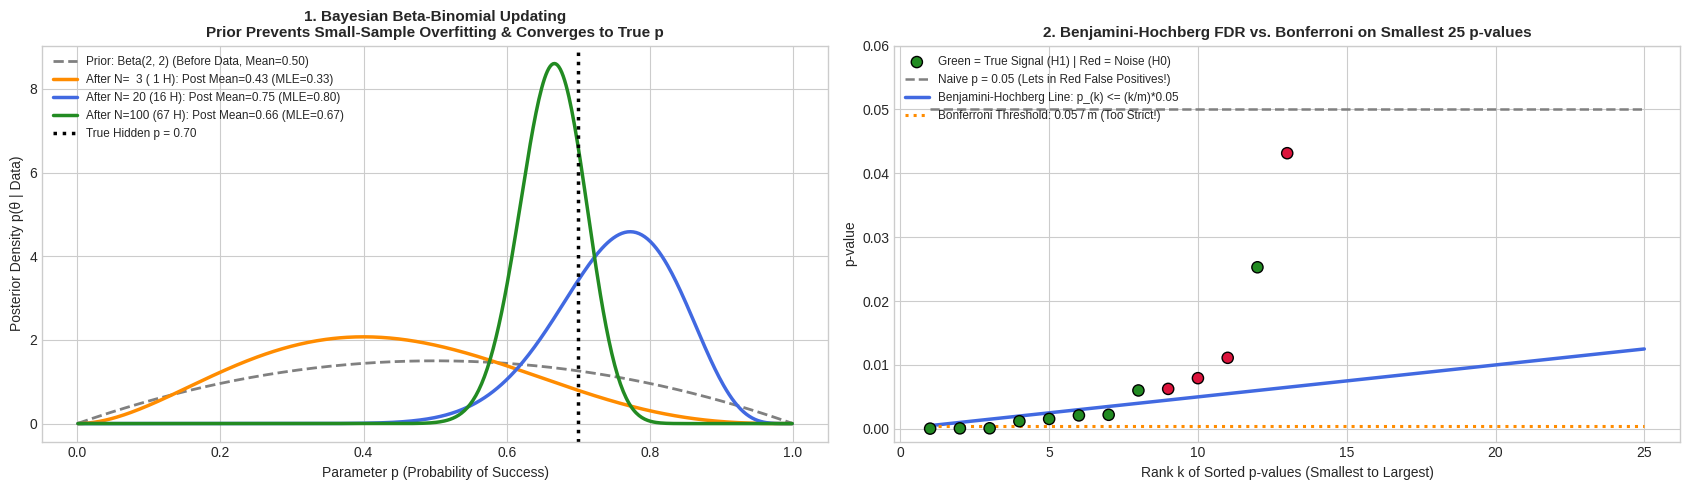

In [11]:
# ==============================================================================
# MODULE 0 (LEVEL 4C): BAYESIAN UPDATING, KL-DIVERGENCE & BENJAMINI-HOCHBERG FDR
# ==============================================================================
from statsmodels.stats.multitest import multipletests

np.random.seed(42)

# 1. Bayesian Beta-Binomial Updating: Watching the Posterior Narrow as Data Arrives
# True hidden coin probability p = 0.70. Start with a conservative Prior Beta(alpha=2, beta=2) centered at 0.50
true_p = 0.70
alpha_prior, beta_prior = 2, 2
theta_grid = np.linspace(0.001, 0.999, 500)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# Left Plot: Sequential Bayesian Updating after N = 0, 3, 20, and 100 flips
axes[0].plot(theta_grid, stats.beta.pdf(theta_grid, alpha_prior, beta_prior),
             color="gray", ls="--", lw=2, label="Prior: Beta(2, 2) (Before Data, Mean=0.50)")

for n_flips, col in [(3, "darkorange"), (20, "royalblue"), (100, "forestgreen")]:
    flips = np.random.binomial(1, true_p, size=n_flips)
    k_heads = np.sum(flips)
    a_post = alpha_prior + k_heads
    b_post = beta_prior + (n_flips - k_heads)
    post_mean = a_post / (a_post + b_post)
    mle_val = k_heads / n_flips
    axes[0].plot(theta_grid, stats.beta.pdf(theta_grid, a_post, b_post), color=col, lw=2.5,
                 label=f"After N={n_flips:3d} ({k_heads:2d} H): Post Mean={post_mean:.2f} (MLE={mle_val:.2f})")

axes[0].axvline(true_p, color="black", ls=":", lw=2.5, label=f"True Hidden p = {true_p:.2f}")
axes[0].set_title("1. Bayesian Beta-Binomial Updating\nPrior Prevents Small-Sample Overfitting & Converges to True p", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Parameter p (Probability of Success)")
axes[0].set_ylabel("Posterior Density p(θ | Data)")
axes[0].legend(fontsize=8.5)

# 2. The Multiple Testing Crisis: 100 Hypothesis Tests (90 Pure Noise H0 + 10 True Signals H1)
m_total = 100
m_null  = 90   # 90 sensors/features have ZERO real effect (H0 is True)
m_alt   = 10   # 10 sensors/features have a REAL effect (H1 is True)

# Simulate Z-scores: 90 from N(0,1) and 10 from N(3.2, 1)
z_null = np.random.normal(0.0, 1.0, size=m_null)
z_alt  = np.random.normal(3.2, 1.0, size=m_alt)
z_all  = np.concatenate([z_null, z_alt])
is_true_signal = np.array([False]*m_null + [True]*m_alt)

# Two-sided p-values
p_vals = 2 * (1 - stats.norm.cdf(np.abs(z_all)))

# Compare 3 Methods at alpha = 0.05: (A) Uncorrected Naive, (B) Bonferroni, (C) Benjamini-Hochberg FDR
rej_naive = p_vals < 0.05
rej_bonf, _, _, _ = multipletests(p_vals, alpha=0.05, method="bonferroni")
rej_bh, _, _, _   = multipletests(p_vals, alpha=0.05, method="fdr_bh")

def summarize_multitest(rejected: np.ndarray, truth: np.ndarray, name: str) -> dict:
    tp = np.sum(rejected & truth)
    fp = np.sum(rejected & (~truth))
    fn = np.sum((~rejected) & truth)
    fdr = fp / max(tp + fp, 1)
    power = tp / np.sum(truth)
    return {
        "Method": name,
        "Total Declared Significant": int(tp + fp),
        "True Positives (Out of 10)": int(tp),
        "False Positives (Fake Alarms)": int(fp),
        "Missed Signals (False Negatives)": int(fn),
        "Empirical Power (Recall)": f"{power*100:.1f}%",
        "False Discovery Proportion": f"{fdr*100:.1f}%"
    }

mt_df = pd.DataFrame([
    summarize_multitest(rej_naive, is_true_signal, "1. Naive Uncorrected (p < 0.05)"),
    summarize_multitest(rej_bonf,  is_true_signal, "2. Bonferroni FWER (p < 0.05 / 100)"),
    summarize_multitest(rej_bh,    is_true_signal, "3. Benjamini-Hochberg FDR (q = 0.05)")
]).set_index("Method")

print("[MULTIPLE HYPOTHESIS TESTING: 90 NOISE FEATURES + 10 TRUE SIGNAL FEATURES]")
display(mt_df)

# Right Plot: Visualizing the Benjamini-Hochberg Step-Up Threshold Line (k/m * alpha)
sorted_idx = np.argsort(p_vals)
sorted_p   = p_vals[sorted_idx]
sorted_truth = is_true_signal[sorted_idx]
ranks = np.arange(1, m_total + 1)

k_zoom = 25  # Zoom into the smallest 25 p-values
colors_pt = ["forestgreen" if t else "crimson" for t in sorted_truth[:k_zoom]]
axes[1].scatter(ranks[:k_zoom], sorted_p[:k_zoom], c=colors_pt, s=65, edgecolor="k", zorder=4,
                label="Green = True Signal (H1) | Red = Noise (H0)")
axes[1].plot(ranks[:k_zoom], [0.05]*k_zoom, color="gray", ls="--", lw=1.8, label="Naive p = 0.05 (Lets in Red False Positives!)")
axes[1].plot(ranks[:k_zoom], (ranks[:k_zoom] / m_total) * 0.05, color="royalblue", lw=2.5,
             label="Benjamini-Hochberg Line: p_(k) <= (k/m)*0.05")
axes[1].plot(ranks[:k_zoom], [0.05 / m_total]*k_zoom, color="darkorange", ls=":", lw=2.2,
             label="Bonferroni Threshold: 0.05 / m (Too Strict!)")

axes[1].set_title("2. Benjamini-Hochberg FDR vs. Bonferroni on Smallest 25 p-values", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Rank k of Sorted p-values (Smallest to Largest)")
axes[1].set_ylabel("p-value")
axes[1].set_ylim(-0.002, 0.06)
axes[1].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

# 🏆 Module 0 Master Takeaways: The Complete Statistical Foundations Bible
*(From High School Intuition to Senior Data Scientist, ML Engineer & AI Engineer Mastery)*

---

## PART 1: High School Statistics — Describing Data & Foundational Probability

### 1.1 The Hierarchy of Data Types (Levels of Measurement)
Choosing the wrong loss function, distance metric, or summary statistic almost always starts with misidentifying the data's scale of measurement:

| Level | Category | Mathematical Property | Permissible Operations | Allowed Central Tendency | Concrete Example |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Nominal** | Categorical | Unordered labels; no quantitative meaning | $=, \neq$ (Counting frequencies, Contingency tables) | **Mode** only | Engine OEM (`GE`, `RR`, `PW`), Blood Type |
| **Ordinal** | Categorical | Strictly ordered ranks, but **unequal intervals** between ranks | $=, \neq, <, >$ (Rank order, Percentiles) | **Mode, Median** | Fault Severity (`Low < Med < High`), Star Ratings |
| **Interval** | Numerical | Equal differences ($1\text{ unit} = 1\text{ unit}$), **NO True Absolute Zero** | $=, \neq, <, >, +, -$ *(Ratios $x_1/x_2$ are invalid!)* | **Mode, Median, Arithmetic Mean** | Temperature in $^\circ\text{C}$ or $^\circ\text{F}$, Calendar Year |
| **Ratio** | Numerical | Equal differences **AND a True Absolute Zero** ($0 =$ complete absence) | All arithmetic: $+, -, \times, \div$, Geometric Mean, $\text{CV}$ | **Mode, Median, Arithmetic/Geometric/Harmonic Mean** | Temperature in Kelvin ($\text{K}$) or Rankine ($^\circ\text{R}$), Mass, Salary, Time-to-Failure |

> **💡 Senior DS Interview Trap:** Why can't you compute the **Coefficient of Variation ($\text{CV} = s / |\bar{x}|$)** on Celsius temperatures? Because Celsius is an **Interval** scale! A dataset with mean $0^\circ\text{C}$ would make $\text{CV} = \infty$, whereas converting the exact same temperatures to Kelvin ($273.15\text{ K}$, a **Ratio** scale) gives a finite, physically meaningful $\text{CV}$.

---

### 1.2 Measures of Center, Breakdown Points & Loss Function Duality
Every summary statistic of location is actually the **minimizer of a specific mathematical loss function**:

1. **Arithmetic Mean ($\bar{x}$ — Minimizer of Squared Error / $L_2$ Loss):**
   $$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i = \arg\min_{c} \sum_{i=1}^{n} (x_i - c)^2$$
   * **Physical Meaning:** Center of gravity (first moment). Every point exerts torque proportional to its distance $(x_i - c)$.
   * **Breakdown Point:** **$0\%$** (a single corrupted observation $x_1 \to \infty$ shifts $\bar{x} \to \infty$).
   * **ML Connection:** Training a model with **MSE ($L_2$ Loss)** forces the model to predict the **Conditional Mean** $\mathbb{E}[Y \mid X]$.

2. **Median ($M$ or $Q_{0.50}$ — Minimizer of Absolute Error / $L_1$ Loss):**
   $$\text{Median}(X) = \arg\min_{c} \sum_{i=1}^{n} |x_i - c|$$
   * **Physical Meaning:** The $50\text{th}$ percentile dividing the sorted dataset into two equal halves. Only the *signs* of the residuals $\text{sign}(x_i - c) \in \{-1, +1\}$ matter, not their magnitudes!
   * **Breakdown Point:** **$50\%$** (up to half the dataset can be corrupted to $\infty$ without moving the median to $\infty$).
   * **ML Connection:** Training a model with **MAE ($L_1$ Loss)** forces the model to predict the **Conditional Median** $\text{Median}(Y \mid X)$. Generally, optimizing the **Pinball / Quantile Loss** $\rho_\tau(u) = u(\tau - \mathbb{I}(u < 0))$ yields the $\tau$-th quantile!

3. **Mode (Minimizer of $L_0$ / Zero-One Loss):**
   $$\text{Mode}(X) = \arg\max_{c} P(X = c) = \arg\min_{c} \sum_{i=1}^{n} \mathbb{I}(x_i \neq c)$$

4. **The Skewness Ordering Rule:**
   * **Left-Skewed (Negative Skew, $\gamma_1 < 0$):** Long left tail pulls Mean down $\implies \mathbf{\text{Mean} < \text{Median} < \text{Mode}}$.
   * **Symmetric ($\gamma_1 = 0$):** $\mathbf{\text{Mean} = \text{Median} = \text{Mode}}$.
   * **Right-Skewed (Positive Skew, $\gamma_1 > 0$):** Long right tail pulls Mean up $\implies \mathbf{\text{Mode} < \text{Median} < \text{Mean}}$.

---

### 1.3 Measures of Spread (Dispersion) & Why We Divide by $n - 1$

| Metric | Formula | Breakdown Point | Properties & Use Case |
| :--- | :--- | :--- | :--- |
| **Range** | $\max(X) - \min(X)$ | $0\%$ | Extremely sensitive to extreme noise; grows monotonically with sample size $n$. |
| **Interquartile Range ($\text{IQR}$)** | $Q_{0.75} - Q_{0.25}$ | $25\%$ | Spread of the middle $50\%$. Used in **Tukey's Boxplot Outlier Rule**: flags points outside $[Q_1 - 1.5\,\text{IQR}, \; Q_3 + 1.5\,\text{IQR}]$. |
| **Median Absolute Deviation ($\text{MAD}$)** | $\text{Median}(|x_i - \text{Median}(X)|)$ | $50\%$ | Most robust dispersion estimator. For Gaussian data, $\hat{\sigma}_{\text{robust}} = 1.4826 \times \text{MAD}$. |
| **Sample Variance ($s^2$)** | $\frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2$ | $0\%$ | Smooth, differentiable, additive across independent random variables. Units are **squared** ($\text{units}^2$). |
| **Standard Deviation ($s$)** | $\sqrt{s^2}$ | $0\%$ | Restores original physical units. |

#### Mathematical Proof of Bessel's Correction ($n - 1$ Degrees of Freedom):
Why does dividing by $n$ underestimate the true population variance $\sigma^2$?
Because the sample mean $\bar{X}$ is closer to the sample points $X_1, \dots, X_n$ than the true population mean $\mu$ is! Algebraically:
$$\sum_{i=1}^{n}(X_i - \mu)^2 = \sum_{i=1}^{n}\left((X_i - \bar{X}) + (\bar{X} - \mu)\right)^2 = \sum_{i=1}^{n}(X_i - \bar{X})^2 + \underbrace{2(\bar{X}-\mu)\sum_{i=1}^{n}(X_i - \bar{X})}_{= 0} + n(\bar{X} - \mu)^2$$
Taking expectations across both sides (using $\mathbb{E}[(X_i - \mu)^2] = \sigma^2$ and $\mathbb{E}[(\bar{X} - \mu)^2] = \text{Var}(\bar{X}) = \frac{\sigma^2}{n}$):
$$\mathbb{E}\left[\sum_{i=1}^{n}(X_i - \bar{X})^2\right] = n\sigma^2 - n\left(\frac{\sigma^2}{n}\right) = (n - 1)\sigma^2 \implies \mathbb{E}\left[\frac{1}{n-1}\sum_{i=1}^{n}(X_i - \bar{X})^2\right] = \sigma^2$$
* **Degrees of Freedom Intuition:** The $n$ residuals $e_i = X_i - \bar{X}$ are subject to 1 linear constraint: $\sum_{i=1}^n e_i = 0$. Once you know the first $n - 1$ residuals, the $n$-th residual is deterministically fixed. Thus, only $n - 1$ independent pieces of information remain to estimate variance!

---

### 1.4 Counting, Probability Axioms & Bayes' Paradox

* **Permutations (Order Matters):** Choosing & arranging $k$ items from $n$:
  $$P(n, k) = \frac{n!}{(n - k)!}$$
* **Combinations (Order Does NOT Matter):** Dividing out the $k!$ internal rearrangements:
  $$\binom{n}{k} = \frac{n!}{k!(n - k)!}$$
* **Mutually Exclusive (Disjoint) vs. Independent Events:**
  * **Mutually Exclusive ($A \cap B = \emptyset$):** Cannot co-occur $\implies P(A \cup B) = P(A) + P(B)$. If $P(A), P(B) > 0$, they are **maximally dependent** because $P(A \mid B) = 0 \neq P(A)$!
  * **Independent ($A \perp B$):** Knowing $B$ occurred tells you nothing about $A \implies P(A \mid B) = P(A)$ and $P(A \cap B) = P(A)P(B)$.
* **Bayes' Theorem & The Base-Rate Fallacy:**
  $$P(A \mid B) = \frac{P(B \mid A)P(A)}{P(B)} = \frac{P(B \mid A)P(A)}{P(B \mid A)P(A) + P(B \mid A^c)P(A^c)}$$
  * **Example:** If a disease affects $1\%$ of people ($P(D)=0.01$) and a test has $99\%$ Sensitivity ($P(+\mid D)=0.99$) and $99\%$ Specificity ($P(-\mid D^c)=0.99 \implies P(+\mid D^c)=0.01$):
    $$P(D \mid +) = \frac{0.99 \times 0.01}{(0.99 \times 0.01) + (0.01 \times 0.99)} = \mathbf{50\%}$$
  * **Engineering Lesson:** When monitoring rare catastrophic events (where base rate $P(\text{Failure}) \ll 1\%$), even a classifier with $99\%$ accuracy will be flooded with False Positives unless Specificity is $99.999\%$+ (which is why we evaluate rare-event ML models using **Precision-Recall AUC** rather than ROC-AUC or Accuracy!).

---

## PART 2: College Statistics I — Random Variables, Distributions & Asymptotic Theorems

### 2.1 Expectation, Variance & Covariance Calculus
Let $X, Y$ be random variables and $a, b, c \in \mathbb{R}$ be constants:
1. **Linearity of Expectation (Always holds, even if $X, Y$ are dependent!):**
   $$\mathbb{E}[aX + bY + c] = a\mathbb{E}[X] + b\mathbb{E}[Y] + c$$
2. **Variance Identity & Quadratic Scaling:**
   $$\text{Var}(X) = \mathbb{E}[(X - \mu_X)^2] = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$$
   $$\text{Var}(aX + bY + c) = a^2\text{Var}(X) + b^2\text{Var}(Y) + 2ab\,\text{Cov}(X, Y)$$
   *(Notice: Constants $c$ shift location but add zero spread; scaling by $a$ multiplies variance by $a^2$; and for independent variables, $\text{Var}(X - Y) = \text{Var}(X) + \text{Var}(Y)$—variances **ADD** even when subtracting two independent random variables!)*
3. **Covariance, Pearson $r$, and Spearman $\rho_s$:**
   $$\text{Cov}(X, Y) = \mathbb{E}[(X - \mu_X)(Y - \mu_Y)] = \mathbb{E}[XY] - \mu_X\mu_Y, \qquad r_{X,Y} = \frac{\text{Cov}(X, Y)}{\sigma_X \sigma_Y} \in [-1, 1]$$
   * **Pearson $r$:** Measures *linear* relationship only; sensitive to outliers. ($X \perp Y \implies r = 0$, but $r = 0 \not\implies X \perp Y$, e.g., $Y = X^2$ on symmetric $[-1, 1]$).
   * **Spearman $\rho_s$:** Pearson correlation computed on the **ranks** of $X$ and $Y$. Captures any strictly monotonic non-linear relationship (e.g., $Y = e^X$ has $\rho_s = 1.0$) and is invariant to monotonic transformations.

---

### 2.2 The 5 Fundamental Distributions & How They Connect

| Distribution | Support | PMF / PDF Formula | Mean $\mathbb{E}[X]$ | Variance $\text{Var}(X)$ | Physical / Engineering Story |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Bernoulli$(p)$** | $k \in \{0, 1\}$ | $p^k(1-p)^{1-k}$ | $p$ | $p(1-p)$ | Single coin flip / binary classification outcome |
| **Binomial$(n, p)$** | $k \in \{0, \dots, n\}$ | $\binom{n}{k}p^k(1-p)^{n-k}$ | $np$ | $np(1-p)$ | Sum of $n$ independent $\text{Bernoulli}(p)$ trials |
| **Poisson$(\lambda)$** | $k \in \{0, 1, 2, \dots\}$ | $\frac{\lambda^k e^{-\lambda}}{k!}$ | $\lambda$ | $\lambda$ | Limit of $\text{Binomial}(n,p)$ as $n\to\infty, p\to 0$ with $np=\lambda$. Counts independent rare events in a fixed window. |
| **Exponential$(\lambda)$** | $t \in [0, \infty)$ | $\lambda e^{-\lambda t}$ | $\frac{1}{\lambda}$ | $\frac{1}{\lambda^2}$ | Continuous waiting time between $\text{Poisson}(\lambda)$ events. **Memoryless:** $P(T > t+s \mid T > s) = P(T > t)$. Constant hazard rate $h(t) = \lambda$. |
| **Normal$\mathcal{N}(\mu, \sigma^2)$** | $x \in (-\infty, \infty)$ | $\frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^2}$ | $\mu$ | $\sigma^2$ | Universal attractor of sums of finite-variance random variables (CLT). |

---

### 2.3 Z-Scores, The 68–95–99.7% Rule & The Two Limit Theorems
* **Z-Score (Standardization):** $Z = \frac{X - \mu}{\sigma} \sim \mathcal{N}(0, 1)$. Measures distance from the mean in units of standard deviation.
  * **$\mu \pm 1\sigma$:** $68.27\%$ | **$\mu \pm 1.96\sigma$:** $95.00\%$ | **$\mu \pm 2\sigma$:** $95.45\%$ | **$\mu \pm 3\sigma$:** $99.73\%$.
* **Law of Large Numbers (LLN):** If $X_1, \dots, X_n$ are i.i.d. with finite $\mathbb{E}[|X|] < \infty$, the sample mean converges in probability to the true mean: $\bar{X}_n \xrightarrow{p} \mu$.
* **Central Limit Theorem (CLT):** If $X_1, \dots, X_n$ are i.i.d. with finite mean $\mu$ and **finite variance $\sigma^2 < \infty$**, then regardless of the shape of the original population, the standardized sample mean converges in distribution to a Standard Normal:
  $$\frac{\bar{X}_n - \mu}{\sigma / \sqrt{n}} \xrightarrow{d} \mathcal{N}(0, 1)$$
  * **When CLT Fails:** Heavy-tailed distributions with **infinite variance** (e.g., $\text{Cauchy}(0,1)$ or $\text{Pareto}(\alpha \le 2)$) never converge to a Normal distribution!

---

## PART 3: College Statistics II — Frequentist Inference, Hypothesis Testing & OLS Regression

### 3.1 Standard Error, Guinness Brewery's $t$-Distribution & Confidence Intervals
* **Standard Deviation ($s$) vs. Standard Error ($\text{SE}$):**
  * $s$ measures the spread of **individual observations** (does *not* shrink as $n \to \infty$).
  * $\text{SE}(\bar{X}) = \frac{s}{\sqrt{n}}$ measures the standard deviation of the **sampling distribution of the sample mean** (shrinks at rate $1/\sqrt{n}$; requires $4\times$ sample size to halve the error).
* **Why Student's $t$-Distribution Exists:** Replacing the unknown true $\sigma$ with the noisy sample estimate $s$ introduces extra denominator randomness in $t = \frac{\bar{X} - \mu}{s / \sqrt{n}}$, creating **heavier tails** governed by $\nu = n - 1$ degrees of freedom. As $n \to \infty$, $t_{\nu} \to \mathcal{N}(0, 1)$.
* **Exact Meaning of a $95\%$ Confidence Interval $\bar{x} \pm t_{\alpha/2, n-1}\frac{s}{\sqrt{n}}$:**
  * **WRONG:** *"There is a $95\%$ probability that $\mu$ lies inside $[48.2, 51.8]$."* ($\mu$ is fixed; the realized numbers $48.2$ and $51.8$ are fixed; probability is either $0$ or $1$).
  * **RIGHT:** *"Across repeated samples of size $n$, $95\%$ of the random intervals $[\bar{X} - t\cdot\text{SE}, \; \bar{X} + t\cdot\text{SE}]$ generated by this procedure will cover the true fixed parameter $\mu$."*

---

### 3.2 Hypothesis Testing Master Reference Table

$$\text{Universal Test Statistic Formula: } \quad \text{Statistic} = \frac{\text{Observed Signal (Difference / Effect)}}{\text{Standard Error of the Signal under } H_0}$$

| Test Name | Use Case / Data Type | Parametric Formula / Statistic | Non-Parametric Equivalent (When Skewed / Outliers) |
| :--- | :--- | :--- | :--- |
| **One-Sample $t$-Test** | Compare 1 sample mean $\bar{x}$ to benchmark $\mu_0$ | $t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}}, \quad \text{df} = n - 1$ | **Wilcoxon Signed-Rank Test** (tests median against $\mu_0$) |
| **Welch's Two-Sample $t$-Test** | Compare means of 2 independent groups ($A, B$) with unequal variances | $t = \frac{\bar{x}_A - \bar{x}_B}{\sqrt{\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}}}$ | **Mann-Whitney U Test** (Wilcoxon Rank-Sum) or **2-Sample Permutation Test** |
| **Paired $t$-Test** | Compare *Before* vs *After* on the **exact same units** ($d_i = x_{B,i} - x_{A,i}$) | $t = \frac{\bar{d}}{s_d / \sqrt{n}}, \quad \text{df} = n - 1$ | **Wilcoxon Signed-Rank Test** on paired differences $d_i$ |
| **One-Way ANOVA ($F$-Test)** | Compare means of $K \ge 3$ independent groups ($H_0: \mu_1 = \dots = \mu_K$) | $F = \frac{\text{MS}_{\text{Between}}}{\text{MS}_{\text{Within}}} = \frac{\text{SS}_B / (K-1)}{\text{SS}_W / (N-K)}$ | **Kruskal-Wallis Test** (ANOVA on ranks) |
| **Chi-Square ($\chi^2$) Test** | Test independence of two categorical variables in a contingency table | $\chi^2 = \sum \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \quad \text{df} = (R-1)(C-1)$ | **Fisher's Exact Test** (for small cell counts $E_{ij} < 5$) |

* **Exact Definition of the $p$-value:** $P(\text{Observing a test statistic at least as extreme as the sample's} \mid H_0 \text{ is TRUE})$. It is **NOT** $P(H_0 \mid \text{Data})$!
* **Type I Error ($\alpha$):** False Positive rate $P(\text{Reject } H_0 \mid H_0 \text{ True})$. Controlled by threshold $\alpha = 0.05$.
* **Type II Error ($\beta$) & Statistical Power ($1 - \beta$):**
  * $\beta = P(\text{Fail to Reject } H_0 \mid H_1 \text{ True})$ (False Negative).
  * $\text{Power} = 1 - \beta = P(\text{Reject } H_0 \mid H_1 \text{ True})$. Power increases with: (1) Larger **Sample Size $n$**, (2) Larger **True Effect Size** (Cohen's $d = \frac{|\mu_A - \mu_B|}{\sigma}$), (3) Smaller **Noise Variance $\sigma^2$**, and (4) Relaxing $\alpha$.

---

### 3.3 Ordinary Least Squares (OLS) Simple Linear Regression
For the model $Y_i = \beta_0 + \beta_1 X_i + \epsilon_i$ with $\epsilon_i \stackrel{\text{i.i.d.}}{\sim} \mathcal{N}(0, \sigma^2)$:
* **Closed-Form Estimators:**
  $$\hat{\beta}_1 = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^n (x_i - \bar{x})^2} = \frac{\text{Cov}(X, Y)}{\text{Var}(X)} = r_{X,Y}\frac{s_Y}{s_X}, \qquad \hat{\beta}_0 = \bar{y} - \hat{\beta}_1\bar{x}$$
* **Variance Decomposition & $R^2$:**
  $$\underbrace{\sum (y_i - \bar{y})^2}_{\text{TSS (Total)}} = \underbrace{\sum (\hat{y}_i - \bar{y})^2}_{\text{ESS (Explained)}} + \underbrace{\sum (y_i - \hat{y}_i)^2}_{\text{RSS (Residual)}}, \qquad R^2 = 1 - \frac{\text{RSS}}{\text{TSS}} = \frac{\text{ESS}}{\text{TSS}}$$
* **Confidence Band (Mean Line) vs. Prediction Band (New Individual Point at $x^*$):**
  $$\text{SE}_{\text{Confidence}}(x^*) = \hat{\sigma}\sqrt{\frac{1}{n} + \frac{(x^* - \bar{x})^2}{\sum(x_i - \bar{x})^2}} \quad \ll \quad \text{SE}_{\text{Prediction}}(x^*) = \hat{\sigma}\sqrt{\mathbf{1} + \frac{1}{n} + \frac{(x^* - \bar{x})^2}{\sum(x_i - \bar{x})^2}}$$
  *(As $n \to \infty$, the Confidence Interval width shrinks to $0$, whereas the Prediction Interval width converges to $\pm 1.96\hat{\sigma}$ because individual observation noise $\epsilon_{\text{new}}$ never vanishes!)*

---

## PART 4: Graduate / Senior DS Statistics — Estimation, Resampling, Bayesian & Information Theory

### 4.1 Point Estimation Theory: Bias-Variance-MSE, Fisher Information & Cramér-Rao Bound
1. **Mean Squared Error Decomposition:**
   $$\text{MSE}(\hat{\theta}) = \mathbb{E}\left[(\hat{\theta} - \theta)^2\right] = \text{Bias}(\hat{\theta})^2 + \text{Var}(\hat{\theta}), \quad \text{where } \text{Bias}(\hat{\theta}) = \mathbb{E}[\hat{\theta}] - \theta$$
2. **Fisher Information $I_n(\theta)$ & Cramér-Rao Lower Bound (CRLB):**
   The variance of **any unbiased estimator** $\hat{\theta}$ is bounded below by the inverse of the Fisher Information (the expected curvature of the log-likelihood):
   $$\text{Var}(\hat{\theta}) \ge \frac{1}{I_n(\theta)} = \frac{1}{-n\,\mathbb{E}\left[\frac{\partial^2}{\partial\theta^2}\ln f(X; \theta)\right]}$$
3. **Maximum Likelihood Estimation (MLE) Asymptotic Properties:**
   Given i.i.d. data, $\hat{\theta}_{\text{MLE}} = \arg\max_\theta \sum_{i=1}^n \ln f(x_i; \theta)$ is:
   * **Consistent:** $\hat{\theta}_{\text{MLE}} \xrightarrow{p} \theta$.
   * **Asymptotically Normal & Efficient (Hits the Cramér-Rao Bound as $n \to \infty$!):**
     $$\sqrt{n}(\hat{\theta}_{\text{MLE}} - \theta) \xrightarrow{d} \mathcal{N}\left(0, \, I_1(\theta)^{-1}\right)$$
   * **Equivariant (Invariance Property):** If $\hat{\theta}$ is the MLE of $\theta$, then $g(\hat{\theta})$ is automatically the MLE of $g(\theta)$!

---

### 4.2 Non-Parametric Resampling: Bootstrap vs. Permutation Tests
* **Non-Parametric Bootstrap (For Confidence Intervals & Standard Errors):**
  * **Mechanism:** Draw $B = 10,000$ resamples of size $n$ **WITH replacement** from your observed sample. Compute any arbitrary statistic $\hat{\theta}^{*(b)}$ (e.g., Median, $P_{90}$, AUC, Sharpe Ratio) on each resample.
  * **Why $63.2\%$ Unique Points per Bootstrap Sample?** Probability a specific point is *never* picked in $n$ draws is $(1 - \frac{1}{n})^n \to e^{-1} \approx 0.368$ ($36.8\%$ Out-of-Bag, $63.2\%$ In-Bag).
* **Exact Permutation Test (For Hypothesis Testing $H_0: F_A = F_B$):**
  * **Mechanism:** Pool groups $A$ and $B$ ($N = n_A + n_B$), shuffle labels **WITHOUT replacement** $B = 10,000$ times, and compute the fraction of shuffled differences exceeding the observed difference:
    $$p_{\text{perm}} = \frac{1 + \sum_{b=1}^B \mathbb{I}(|\Delta^{*(b)}| \ge |\Delta_{\text{obs}}|)}{B + 1}$$

---

### 4.3 Bayesian Inference & The Regularization Equivalence Theorem
* **Bayes' Updating Rule:** $\text{Posterior } p(\theta \mid D) \propto \text{Likelihood } p(D \mid \theta) \times \text{Prior } p(\theta)$.
* **Conjugate Priors (Analytical Closed-Form Posteriors):**
  * **Beta Prior + Binomial Likelihood $\implies$ Beta Posterior:** $\text{Beta}(\alpha_0, \beta_0) + (k \text{ heads}, n-k \text{ tails}) \implies \text{Beta}(\alpha_0 + k, \, \beta_0 + n - k)$.
  * **Gamma Prior + Poisson Likelihood $\implies$ Gamma Posterior.**
  * **Normal Prior + Normal Likelihood $\implies$ Normal Posterior** (precision $\tau = 1/\sigma^2$ adds linearly: $\tau_{\text{post}} = \tau_{\text{prior}} + n\tau_{\text{data}}$).
* **Why Regularized ML IS Bayesian MAP Estimation:**
  Maximizing $\ln p(w \mid D) = \ln p(D \mid w) + \ln p(w)$ under Gaussian errors $y_i \sim \mathcal{N}(w^T x_i, \sigma^2)$:
  1. **Uniform (Flat) Prior $p(w) \propto 1$:** $\implies$ **MLE / Ordinary Least Squares (OLS)**.
  2. **Gaussian Prior $w_j \sim \mathcal{N}(0, \tau^2)$:** $\ln p(w) \propto -\frac{1}{2\tau^2}\sum w_j^2 \implies$ **Ridge Regression ($L_2$ Penalty, $\lambda = \sigma^2/\tau^2$)**.
  3. **Laplace Prior $w_j \sim \text{Laplace}(0, b)$:** $\ln p(w) \propto -\frac{1}{b}\sum |w_j| \implies$ **Lasso Regression ($L_1$ Penalty, sparse feature selection)**.

---

### 4.4 Information Theory & High-Dimensional Multiple Testing
* **Shannon Entropy:** $H(P) = -\mathbb{E}_{x\sim P}[\ln P(x)]$.
* **KL-Divergence (Relative Entropy):**
  $$D_{\text{KL}}(P \parallel Q) = \sum P(x)\ln\left(\frac{P(x)}{Q(x)}\right) = \underbrace{H(P, Q)}_{\text{Cross-Entropy}} - \underbrace{H(P)}_{\text{Entropy of Truth}} \ge 0$$
  *(Minimizing Cross-Entropy Loss in deep learning is mathematically identical to minimizing the KL-Divergence between empirical labels $P$ and predicted softmax probabilities $Q$!)*
* **Multiple Hypothesis Testing ($m$ simultaneous tests at level $\alpha$):**
  * **Naive Uncorrected:** Expected False Positives $= m\alpha$; Family-Wise Error Rate $\text{FWER} = 1 - (1-\alpha)^m \to 100\%$.
  * **Bonferroni Correction (Controls FWER — Probability of $\ge 1$ False Positive):** Reject if $p_i \le \frac{\alpha}{m}$. Conservative; suffers from high False Negatives (low power) when $m$ is large.
  * **Benjamini-Hochberg (BH) Step-Up Procedure (Controls False Discovery Rate, $\text{FDR} = \mathbb{E}\left[\frac{\text{FP}}{\text{FP} + \text{TP}}\right] \le q$):** Sort $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$, find the largest $k$ where $p_{(k)} \le \frac{k}{m}q$, and reject $H_0$ for all $i \le k$. Preserves high statistical power in high-dimensional feature screening!

### 🐙 Cloning and Managing Your GitHub Repository in Colab
Use this cell to securely clone your repository using your Colab Secrets and create a proper directory structure.

In [16]:
import os
from google.colab import userdata

# 1. Retrieve your GITHUB_TOKEN from Colab Secrets securely
try:
    token = userdata.get('GITHUB_TOKEN')
    print("🔑 GITHUB_TOKEN detected successfully in Secrets.")
except Exception as e:
    print("❌ GITHUB_TOKEN not found in your Secrets!")
    print("Please click the '🔑 (Secrets)' icon on the left panel, add a new secret named GITHUB_TOKEN, paste your token, and enable notebook access.")
    token = None

if token:
    # 2. Configure repository settings
    username = "Abhilash0708"
    repo_name = "Knowledge-Preparation-Interview"
    repo_url = f"https://{token}@github.com/{username}/{repo_name}.git"

    # 3. Clone the repository to Colab's workspace
    if not os.path.exists(f"/content/{repo_name}"):
        !git clone {repo_url} /content/{repo_name}
        print(f"✅ Successfully cloned {repo_name}!")
    else:
        print(f"ℹ️ Directory /content/{repo_name} already exists.")

🔑 GITHUB_TOKEN detected successfully in Secrets.
Cloning into '/content/Knowledge-Preparation-Interview'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), 12.68 KiB | 999.00 KiB/s, done.
✅ Successfully cloned Knowledge-Preparation-Interview!


### 📂 Organizing Folders and Committing Notebooks
Run the cell below to set your Git configurations, create customized folders (such as `statistics/module_0_foundations`), copy your files there, and push them back to your repository.

In [17]:
# 1. Verify that the repository directory exists before navigating
import os

repo_dir = "/content/Knowledge-Preparation-Interview"

if os.path.exists(repo_dir):
    %cd {repo_dir}

    # 2. Configure global git identifiers
    !git config --global user.name "Abhilash0708"
    !git config --global user.email "your_email@example.com" # <- Update with your email

    # 3. Design and create your preferred folder structure inside the repo
    folder_path = "statistics/module_0_foundations"
    os.makedirs(folder_path, exist_ok=True)
    print(f"📁 Created folder structure: {repo_dir}/{folder_path}")

    # 4. Check status
    !git status
else:
    print("❌ Repository folder not found. Please ensure Step 1 is completed and your GITHUB_TOKEN secret is configured correctly before running this cell.")

/content/Knowledge-Preparation-Interview
📁 Created folder structure: /content/Knowledge-Preparation-Interview/statistics/module_0_foundations
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [18]:
import os

# 1. Ensure we are in the correct repository folder
repo_dir = "/content/Knowledge-Preparation-Interview"
if os.path.exists(repo_dir):
    %cd {repo_dir}

    # 2. Let's create a placeholder or copy the content into a notebook file in the folder
    # We'll save a descriptive markdown file as a start to verify the push
    target_file_path = "statistics/module_0_foundations/README.md"
    os.makedirs(os.path.dirname(target_file_path), exist_ok=True)

    with open(target_file_path, "w") as f:
        f.write("# Module 0: Statistics from the Ground Up\n\nWelcome to the complete Statistical Foundations bible. This module covers descriptive statistics, probability theory, classical hypothesis testing, regression analysis, point estimation, computational resampling, and Bayesian inference.\n")

    print("📝 Created README.md in statistics/module_0_foundations/")

    # 3. Add files, commit, and push to the remote repository 'main' branch
    print("\n📤 Staging and committing files...")
    !git add statistics/
    !git commit -m "docs: Add Module 0 foundations initial folder structure and README"

    print("\n🚀 Pushing to GitHub main branch...")
    !git push origin main
else:
    print("❌ Repository folder not found. Please verify the cloning step was executed successfully.")

/content/Knowledge-Preparation-Interview
📝 Created README.md in statistics/module_0_foundations/

📤 Staging and committing files...
[main a9a9223] docs: Add Module 0 foundations initial folder structure and README
 1 file changed, 3 insertions(+)
 create mode 100644 statistics/module_0_foundations/README.md

🚀 Pushing to GitHub main branch...
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (5/5), 611 bytes | 611.00 KiB/s, done.
Total 5 (delta 0), reused 0 (delta 0), pack-reused 0
To https://github.com/Abhilash0708/Knowledge-Preparation-Interview.git
   6b66c30..a9a9223  main -> main


### 📤 Locate and Push This Active Notebook (`.ipynb`) to GitHub
Run the cell below to automatically detect this current notebook, copy it into your repository's target directory (`statistics/module_0_foundations/`), commit, and push it up to GitHub!

In [ ]:
import os
import glob
import shutil

# 1. Define paths
repo_dir = "/content/Knowledge-Preparation-Interview"
target_folder = os.path.join(repo_dir, "statistics/module_0_foundations")
target_filename = "module_0_statistical_foundations.ipynb"
target_path = os.path.join(target_folder, target_filename)
notebook_saved = False

# 2. Extract using Google Drive API via precise File ID
print("🛰️ Resolving active notebook from Drive using File ID...")
try:
    from google.colab import auth
    auth.authenticate_user()

    from googleapiclient.discovery import build
    import io
    from googleapiclient.http import MediaIoBaseDownload

    drive_service = build('drive', 'v3')
    file_id = '1RkZ3-xs7AxGqQ_vWrn3-t41IPjVOf2CZ'

    request = drive_service.files().get_media(fileId=file_id)
    fh = io.BytesIO()
    downloader = MediaIoBaseDownload(fh, request)
    done = False
    while not done:
        status, done = downloader.next_chunk()

    os.makedirs(target_folder, exist_ok=True)
    with open(target_path, 'wb') as f:
        f.write(fh.getvalue())

    print(f"💾 Successfully downloaded active notebook to target: {target_path}")
    notebook_saved = True
except Exception as e:
    print(f"⚠️ API-based download failed: {e}")

# 3. Fallback: Search folder heuristic if API fails
if not notebook_saved:
    print("🔄 Trying fallback: Searching Colab Notebooks directory on Drive...")
    try:
        from google.colab import drive
        drive.mount('/content/gdrive', force_remount=True)
        drive_path = "/content/gdrive/MyDrive/Colab Notebooks"
        candidates = glob.glob(os.path.join(drive_path, "*Statistical*.ipynb"))
        if candidates:
            shutil.copy(candidates[0], target_path)
            print(f"💾 Successfully copied from Drive candidate: {target_path}")
            notebook_saved = True
    except Exception as fallback_err:
        print(f"❌ Fallback failed: {fallback_err}")

# 4. Git commit and push
if notebook_saved and os.path.exists(repo_dir):
    %cd {repo_dir}

    print("\n📤 Staging and committing the notebook...")
    !git add statistics/
    !git commit -m "feat: Add complete Module 0 statistical foundations notebook" --allow-empty

    print("\n🚀 Pushing changes to GitHub main branch...")
    !git push origin main
else:
    print("\n❌ Could not save the notebook. Please save this notebook manually.")

🛰️ Resolving active notebook from Drive using File ID...
